# UK Gender Pay Gap — Correlation Heatmap & Median Pay Gap Over Time
**Author:** Nick

Positive pay-gap values mean men earn more than women; negative values mean women earn more.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# The CSV sits in the repo root, one level up from the Nick/ folder
df = pd.read_csv("../UK_Gender_Pay_Gap_workbook_allyears.csv", encoding="utf-8-sig")
print(df.shape)
df.head()

(48711, 31)


,EmployerId,Address,PostCode,PostCodeAbbrv,REGION,CompanyNumber,SicCodes,Cleaned SIC,Industry,DiffMeanHourlyPercent,...,MaleTopQuartile,FemaleTopQuartile,CompanyLinkToGPGInfo,ResponsiblePerson,EmployerSize,CurrentName,SubmittedAfterTheDeadline,DueDate,DateSubmitted,ReportingPeriod
0,676,"Bryanston House, Blandford, Dorset, DT11 0PX",DT11 0PX,DT,Dorchester,00226143,85310,85310,Education,18.0,...,51.5,48.5,https://www.bryanston.co.uk/employment,Nick McRobb (Bursar and Clerk to the Governors),500 to 999,BRYANSTON SCHOOL INCORPORATED,False,4/5/2018 0:00,3/27/2018 11:42,2017-2018
1,16879,"19 Smith's Place, Leith Walk, Edinburgh, EH6 8NU",EH6 8NU,EH,Edinburgh,SC016876,47730,47730,Wholesale & Retail Trade,2.3,...,18.1,81.9,NaN,Philip Galt (Managing Director),250 to 499,"""RED BAND"" CHEMICAL COMPANY, LIMITED",False,4/5/2018 0:00,3/28/2018 16:44,2017-2018
2,17677,"34 Roundhay Road, Leeds, England, LS7 1AB",LS7 1AB,LS,Leeds,10530651,78300,78300,AdministrativeServices,41.0,...,23.0,77.0,NaN,Chloe Lines (Financial Controller),250 to 499,123 EMPLOYEES LTD,True,4/5/2018 0:00,5/4/2018 11:24,2017-2018
3,682,"Trinity Sports And Leisure, Chilton Street, Br...",TA6 3JA,TA,Taunton,06727055,93110,93110,Arts/Entertainment,-22.0,...,24.0,76.0,https://www.1610.org.uk/gender-pay-gap/,Tim Nightingale (CEO),250 to 499,1610 LIMITED,True,4/5/2018 0:00,4/12/2018 17:03,2017-2018
4,17101,"The Sunderland Stadium Of Light, Sunderland, T...",SR5 1SU,SR,Sunderland,07743495,"56210,\n70229","5,621,070,229",Accommodation/Food_Service,13.4,...,58.2,41.8,https://www.safc.com/news/club-news/2018/march...,Jo Graham (Deputy HR Manager),250 to 499,1879 EVENTS MANAGEMENT LIMITED,False,4/5/2018 0:00,3/29/2018 15:32,2017-2018


## 1. Correlation heatmap

The male quartile columns are just `100 − female quartile`, so including both would only add perfect −1 correlations. We keep the pay-gap measures, the bonus-receipt rates, and the **female share** of each pay quartile.

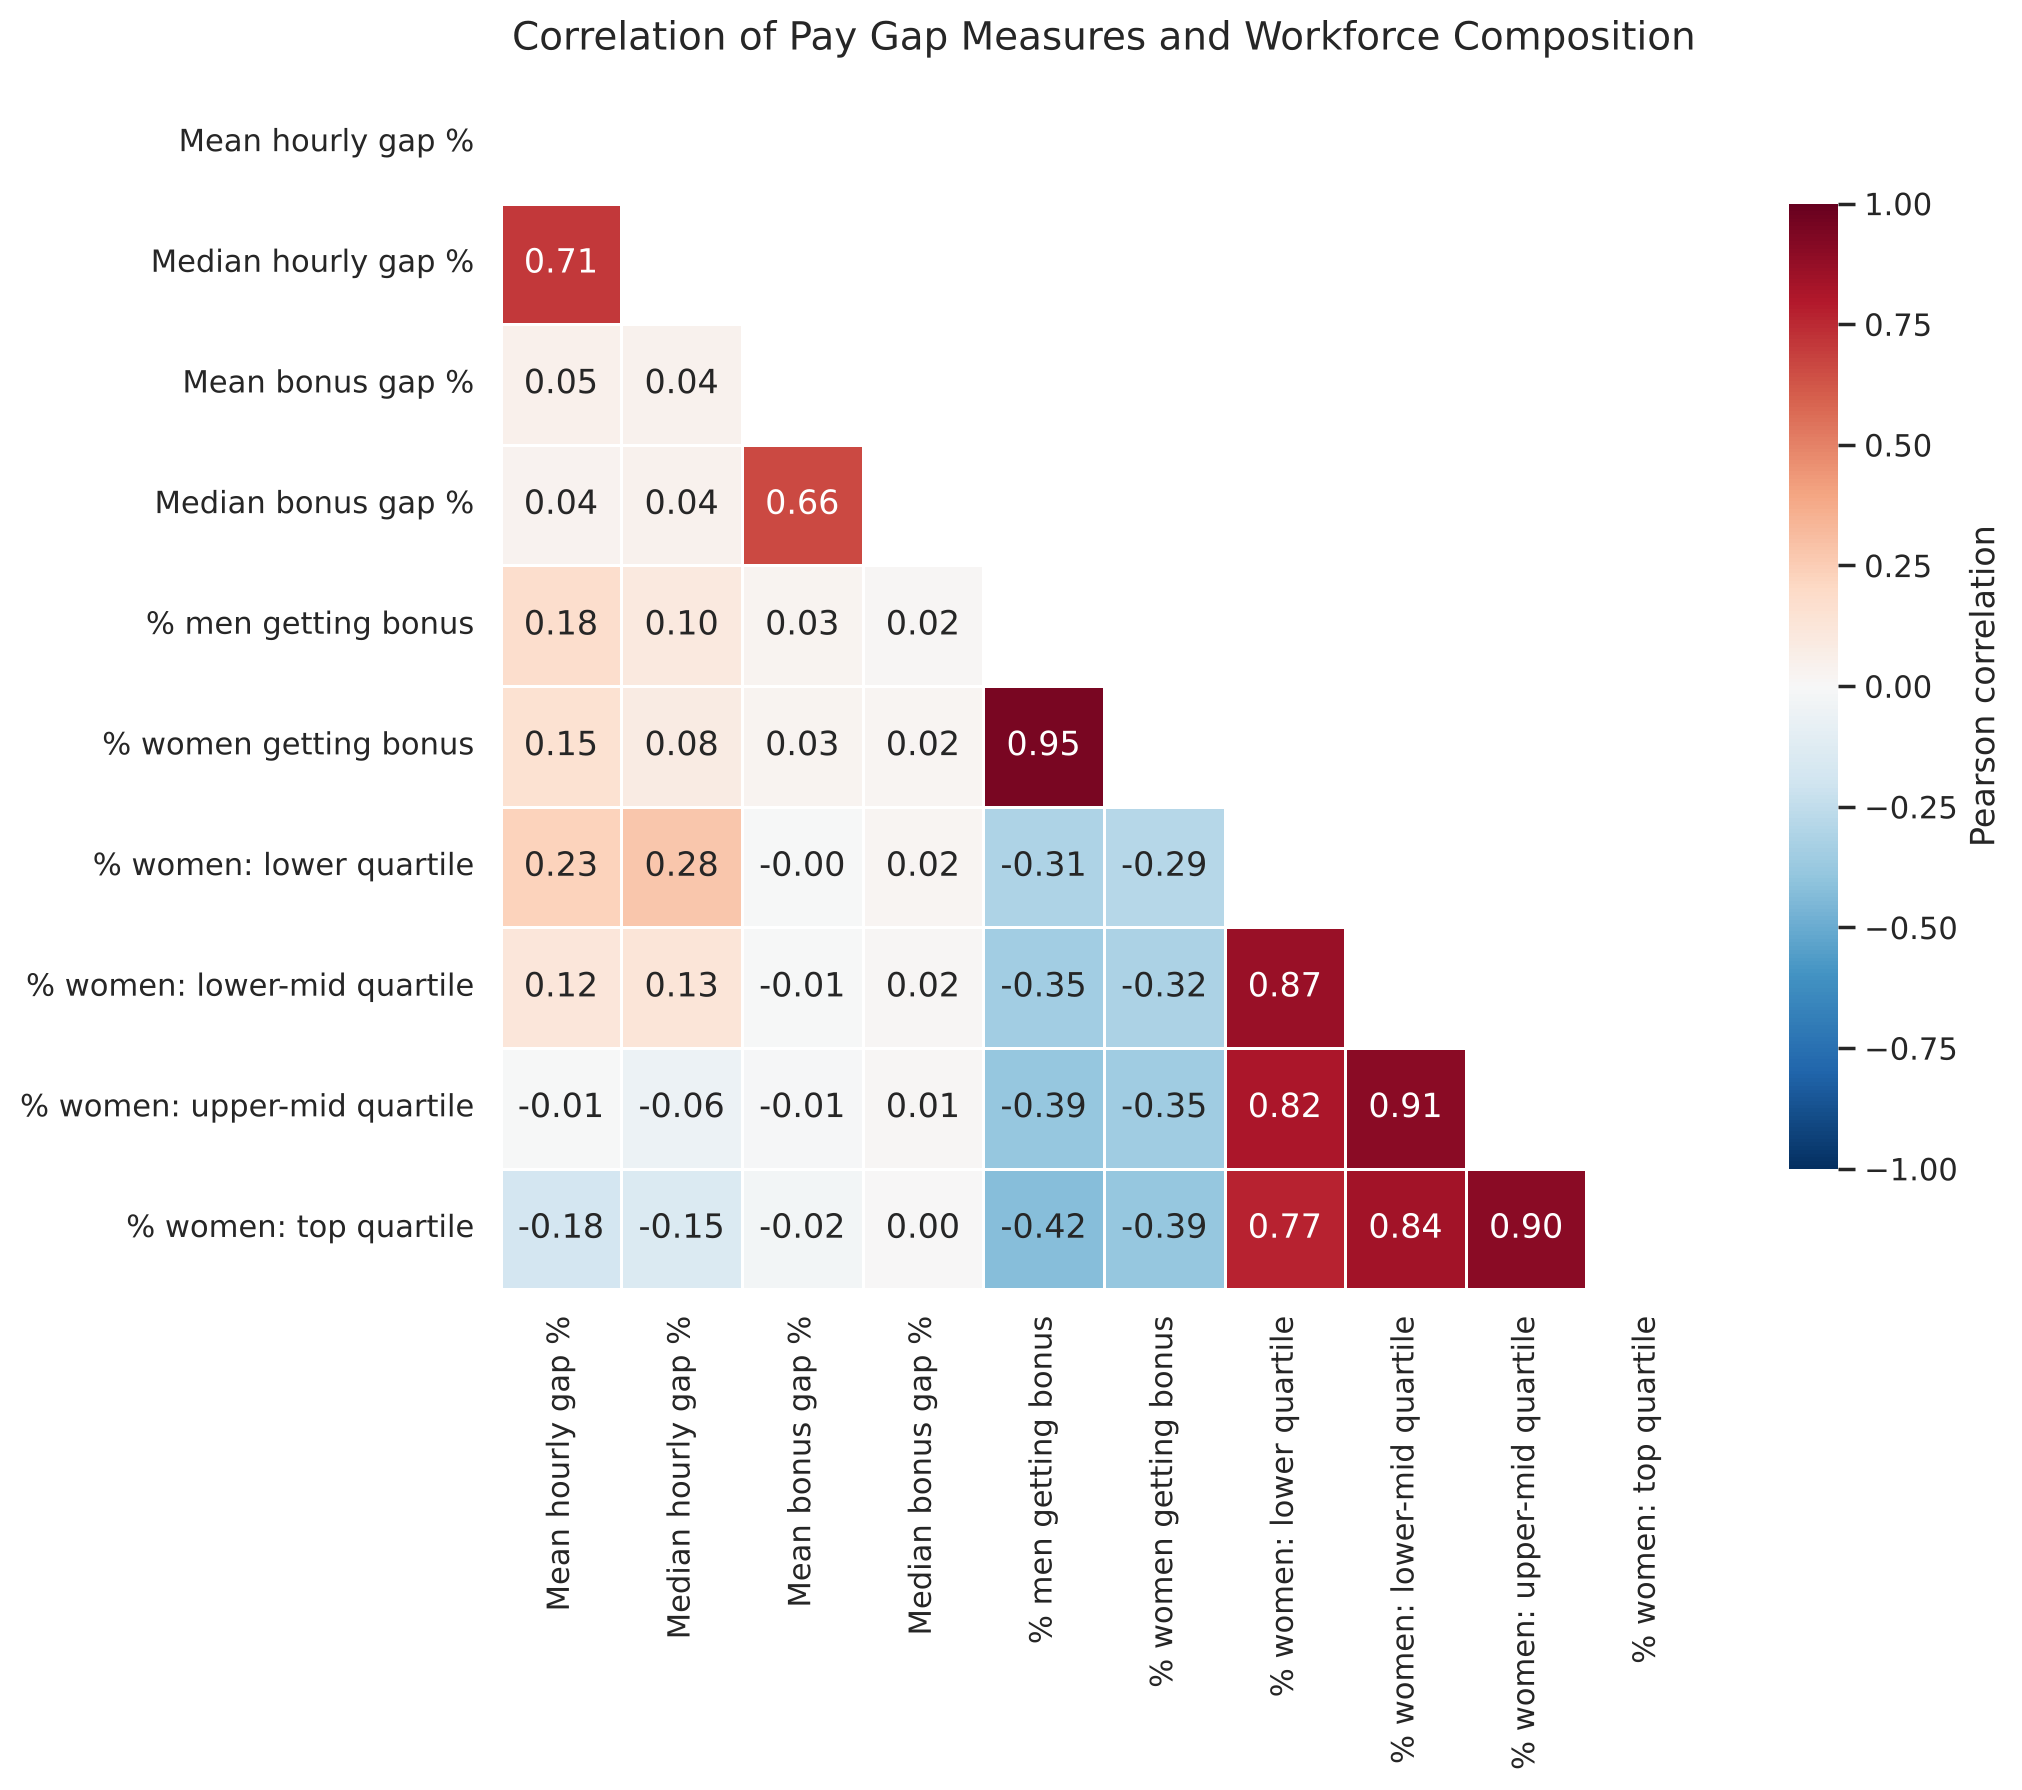

In [2]:
corr_cols = {
    "DiffMeanHourlyPercent":     "Mean hourly gap %",
    "DiffMedianHourlyPercent":   "Median hourly gap %",
    "DiffMeanBonusPercent":      "Mean bonus gap %",
    "DiffMedianBonusPercent":    "Median bonus gap %",
    "MaleBonusPercent":          "% men getting bonus",
    "FemaleBonusPercent":        "% women getting bonus",
    "FemaleLowerQuartile":       "% women: lower quartile",
    "FemaleLowerMiddleQuartile": "% women: lower-mid quartile",
    "FemaleUpperMiddleQuartile": "% women: upper-mid quartile",
    "FemaleTopQuartile":         "% women: top quartile",
}

corr = df[list(corr_cols)].rename(columns=corr_cols).corr()

# Show only the lower triangle (the upper half is a mirror image)
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r",
            vmin=-1, vmax=1, center=0, square=True, linewidths=0.5,
            cbar_kws={"shrink": 0.8, "label": "Pearson correlation"}, ax=ax)
ax.grid(False)
ax.set_title("Correlation of Pay Gap Measures and Workforce Composition", fontsize=14, pad=12)
plt.tight_layout()
plt.show()

**Note on bonus gaps:** the bonus gap columns contain some extreme outliers (very large negative values), which can weaken their correlations. A Spearman (rank-based) version is less sensitive to that:

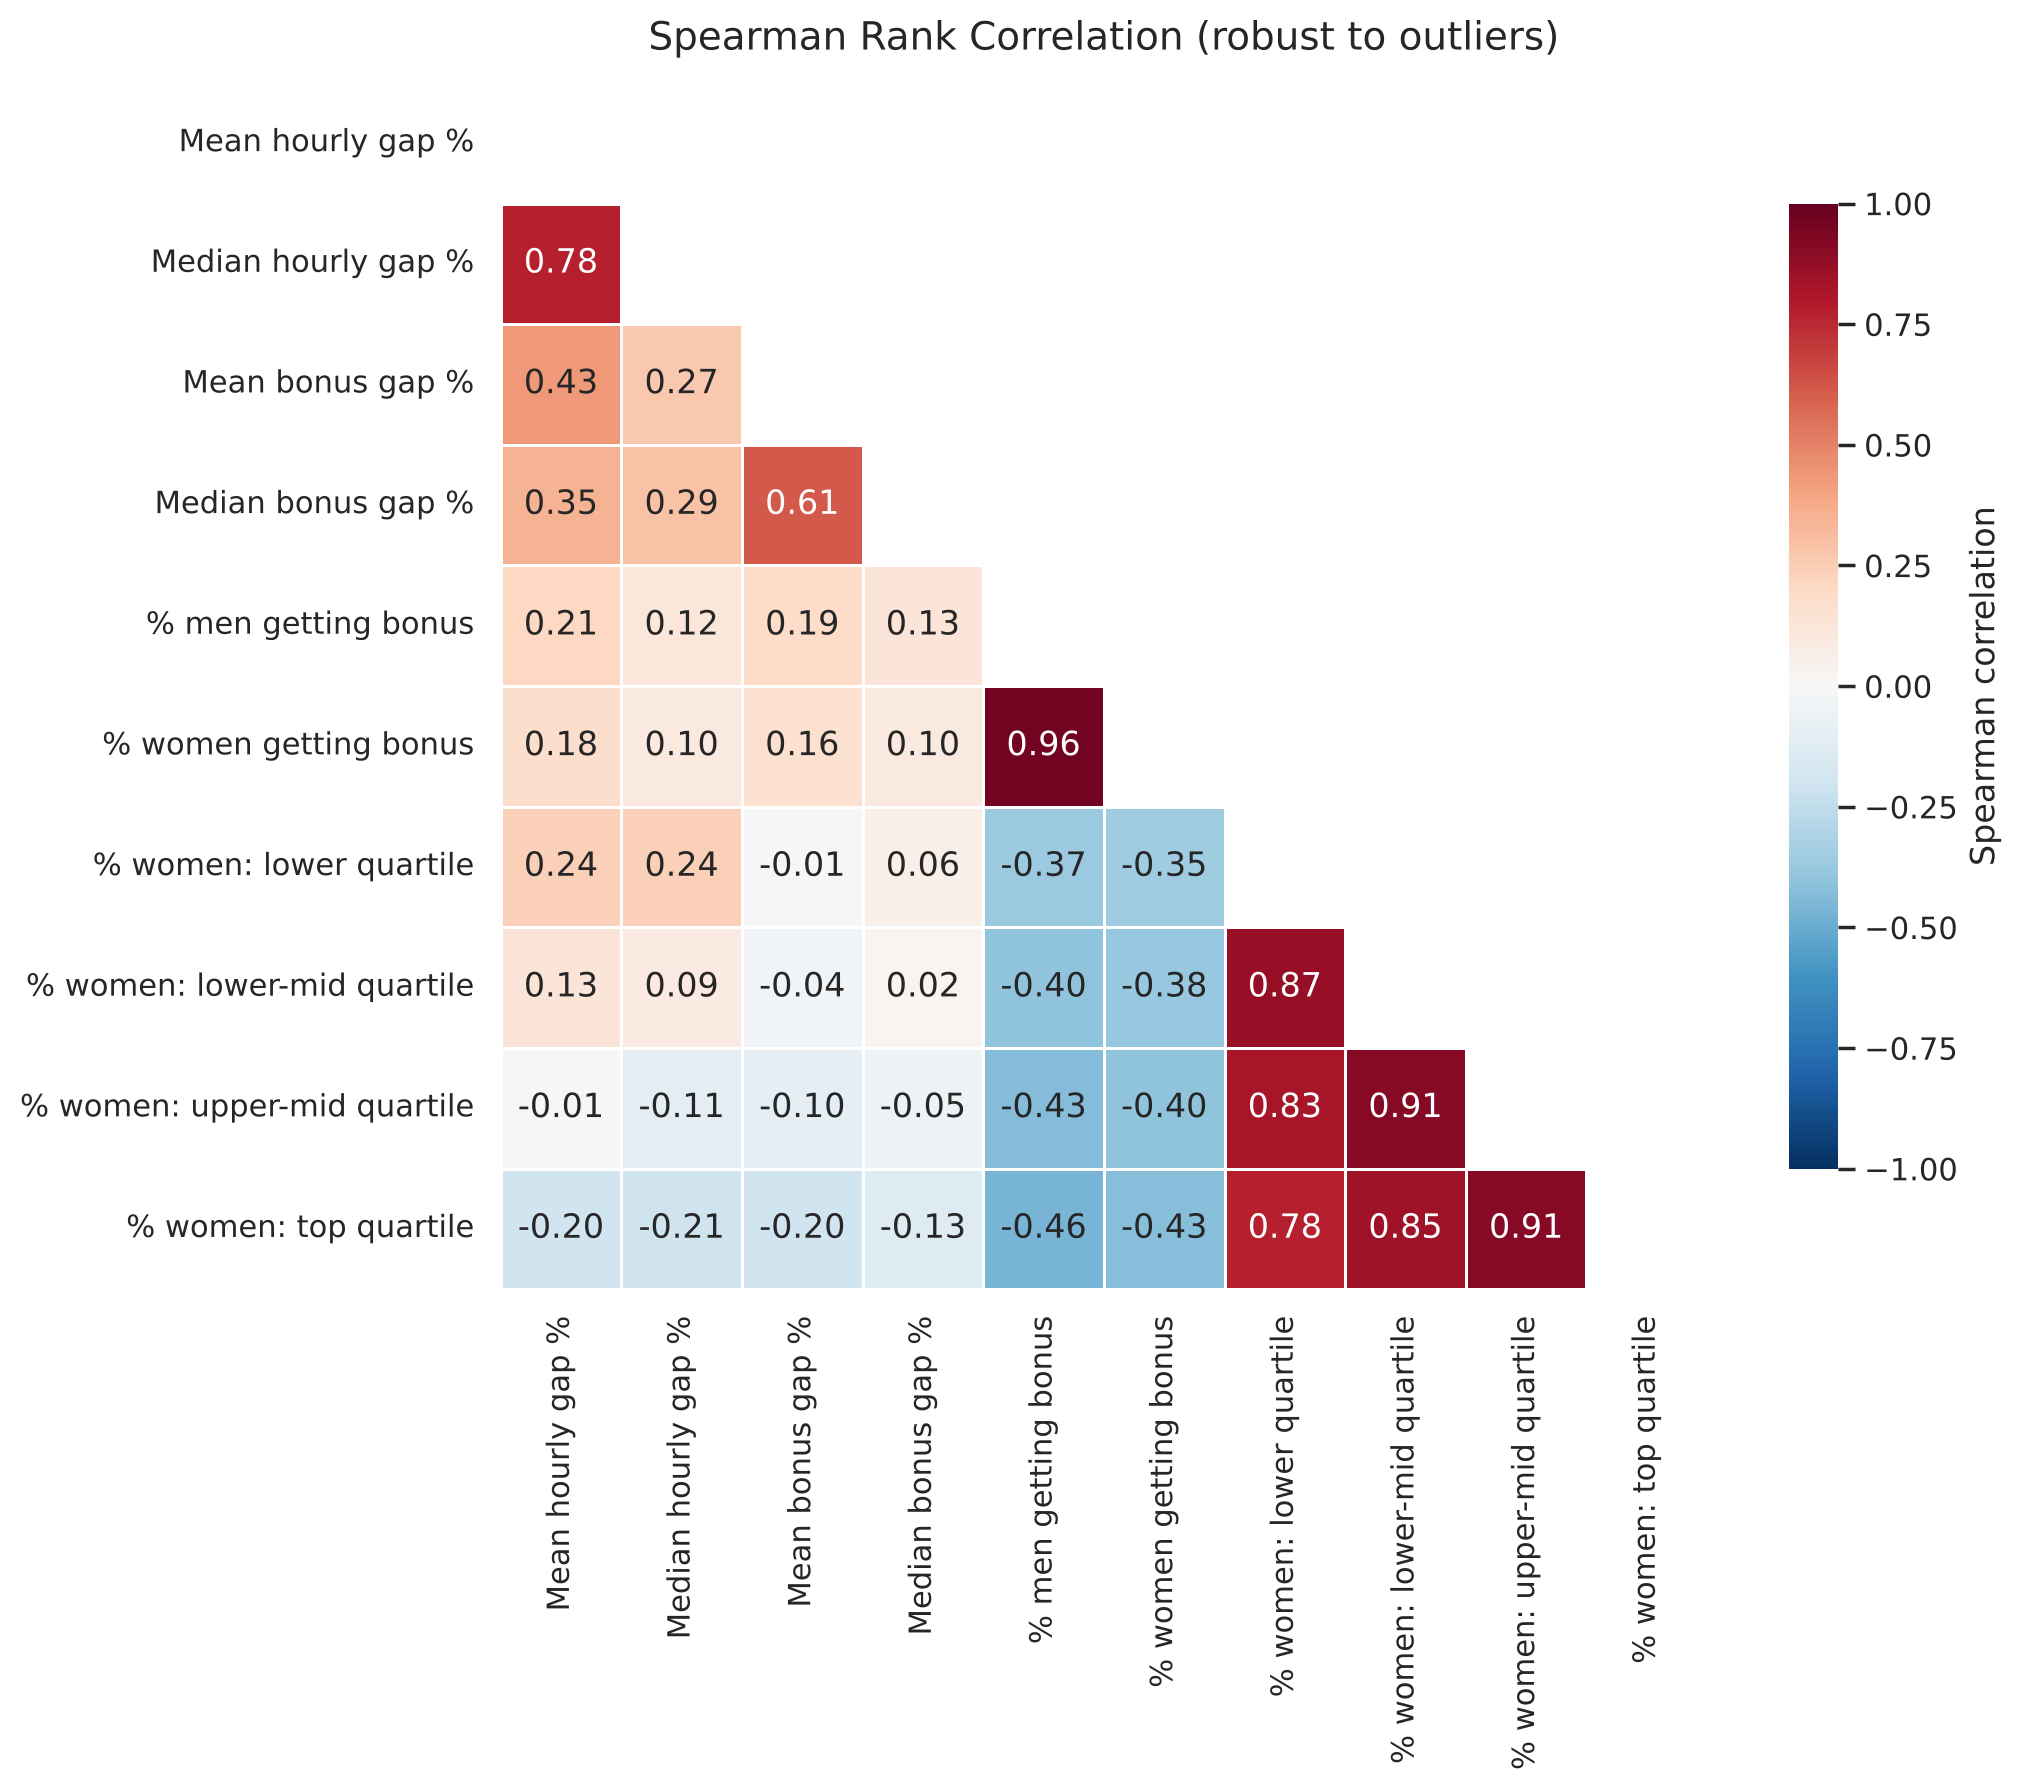

In [3]:
corr_s = df[list(corr_cols)].rename(columns=corr_cols).corr(method="spearman")

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr_s, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r",
            vmin=-1, vmax=1, center=0, square=True, linewidths=0.5,
            cbar_kws={"shrink": 0.8, "label": "Spearman correlation"}, ax=ax)
ax.grid(False)
ax.set_title("Spearman Rank Correlation (robust to outliers)", fontsize=14, pad=12)
plt.tight_layout()
plt.show()

## 2. Change in median pay gap over the years

For each reporting period we take the **median across employers** of `DiffMedianHourlyPercent` (the median makes it robust to outlier companies). The 2022-2023 period is dropped because it only has ~125 reports — the data was pulled before most employers had filed, so it isn't comparable.

In [4]:
print(df["ReportingPeriod"].value_counts().sort_index())

df_years = df[df["ReportingPeriod"] != "2022-2023"]

yearly = (df_years.groupby("ReportingPeriod")["DiffMedianHourlyPercent"]
          .agg(median_gap="median", mean_gap="mean", n_employers="count")
          .reset_index())
yearly

ReportingPeriod
2017-2018    10230
2018-2019    10471
2019-2020     6924
2020-2021    10536
2021-2022    10425
2022-2023      125
Name: count, dtype: int64


,ReportingPeriod,median_gap,mean_gap,n_employers
0,2017-2018,9.4,11.868152,10230
1,2018-2019,9.7,11.979286,10471
2,2019-2020,10.5,12.785471,6924
3,2020-2021,10.0,12.451016,10536
4,2021-2022,9.7,12.199137,10425


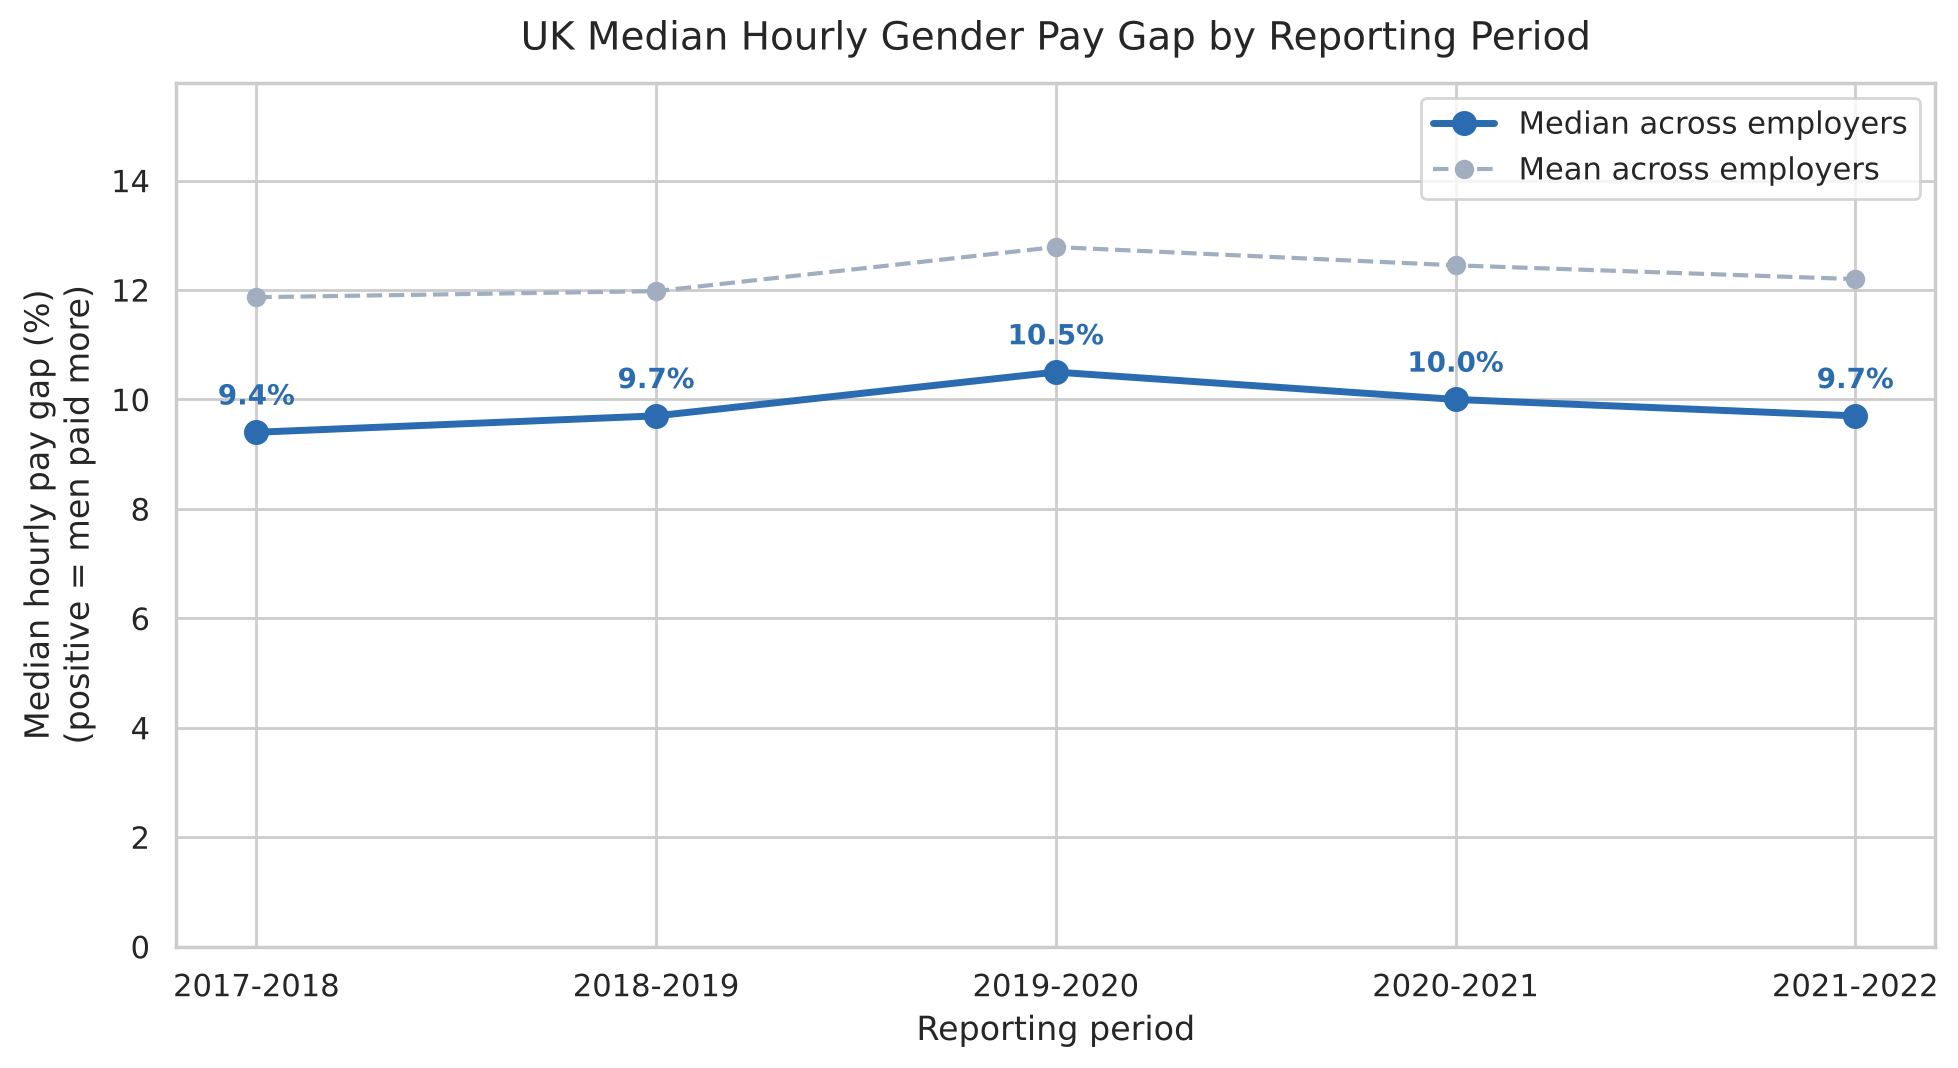

Change from 2017-2018 to 2021-2022: +0.3 percentage points


In [5]:
fig, ax = plt.subplots(figsize=(10, 5.5))

ax.plot(yearly["ReportingPeriod"], yearly["median_gap"], marker="o",
        linewidth=2.5, markersize=8, color="#2b6cb0", label="Median across employers")
ax.plot(yearly["ReportingPeriod"], yearly["mean_gap"], marker="o",
        linewidth=1.5, linestyle="--", color="#a0aec0", label="Mean across employers")

for x, y in zip(yearly["ReportingPeriod"], yearly["median_gap"]):
    ax.annotate(f"{y:.1f}%", (x, y), textcoords="offset points", xytext=(0, 10),
                ha="center", fontsize=10, fontweight="bold", color="#2b6cb0")

ax.set_title("UK Median Hourly Gender Pay Gap by Reporting Period", fontsize=14, pad=12)
ax.set_xlabel("Reporting period")
ax.set_ylabel("Median hourly pay gap (%)\n(positive = men paid more)")
ax.set_ylim(0, yearly[["median_gap", "mean_gap"]].max().max() + 3)
ax.legend()
plt.tight_layout()
plt.show()

change = yearly["median_gap"].iloc[-1] - yearly["median_gap"].iloc[0]
print(f"Change from {yearly['ReportingPeriod'].iloc[0]} to {yearly['ReportingPeriod'].iloc[-1]}: {change:+.1f} percentage points")

**Note:** 2019-2020 has fewer reports (~6,900 vs ~10,000+) because the UK government suspended enforcement of reporting during COVID-19, so that year's figure is based on a smaller, possibly less representative group of employers.

## 3. Checking for bias by reporting year

Before pooling all years together for modelling, we check whether any reporting year looks different from the others. Three things have to agree:
1. **The middle** of the pay gap doesn't move much from year to year.
2. **The spread** doesn't move much either (a matching median could hide one year with far more extreme employers).
3. **The mix of employers** reporting each year stays the same (otherwise a shift could come from *who* reported, not from pay).

The 2022-2023 period stays excluded (only ~125 reports).

In [6]:
target = "DiffMedianHourlyPercent"

# Reports per year and summary of the pay gap per year
print(df_years["ReportingPeriod"].value_counts().sort_index())
df_years.groupby("ReportingPeriod")[target].agg(["mean", "median", "std"]).round(1)

ReportingPeriod
2017-2018    10230
2018-2019    10471
2019-2020     6924
2020-2021    10536
2021-2022    10425
Name: count, dtype: int64


,mean,median,std
ReportingPeriod,,,
2017-2018,11.9,9.4,15.9
2018-2019,12.0,9.7,15.5
2019-2020,12.8,10.5,15.4
2020-2021,12.5,10.0,17.7
2021-2022,12.2,9.7,17.0


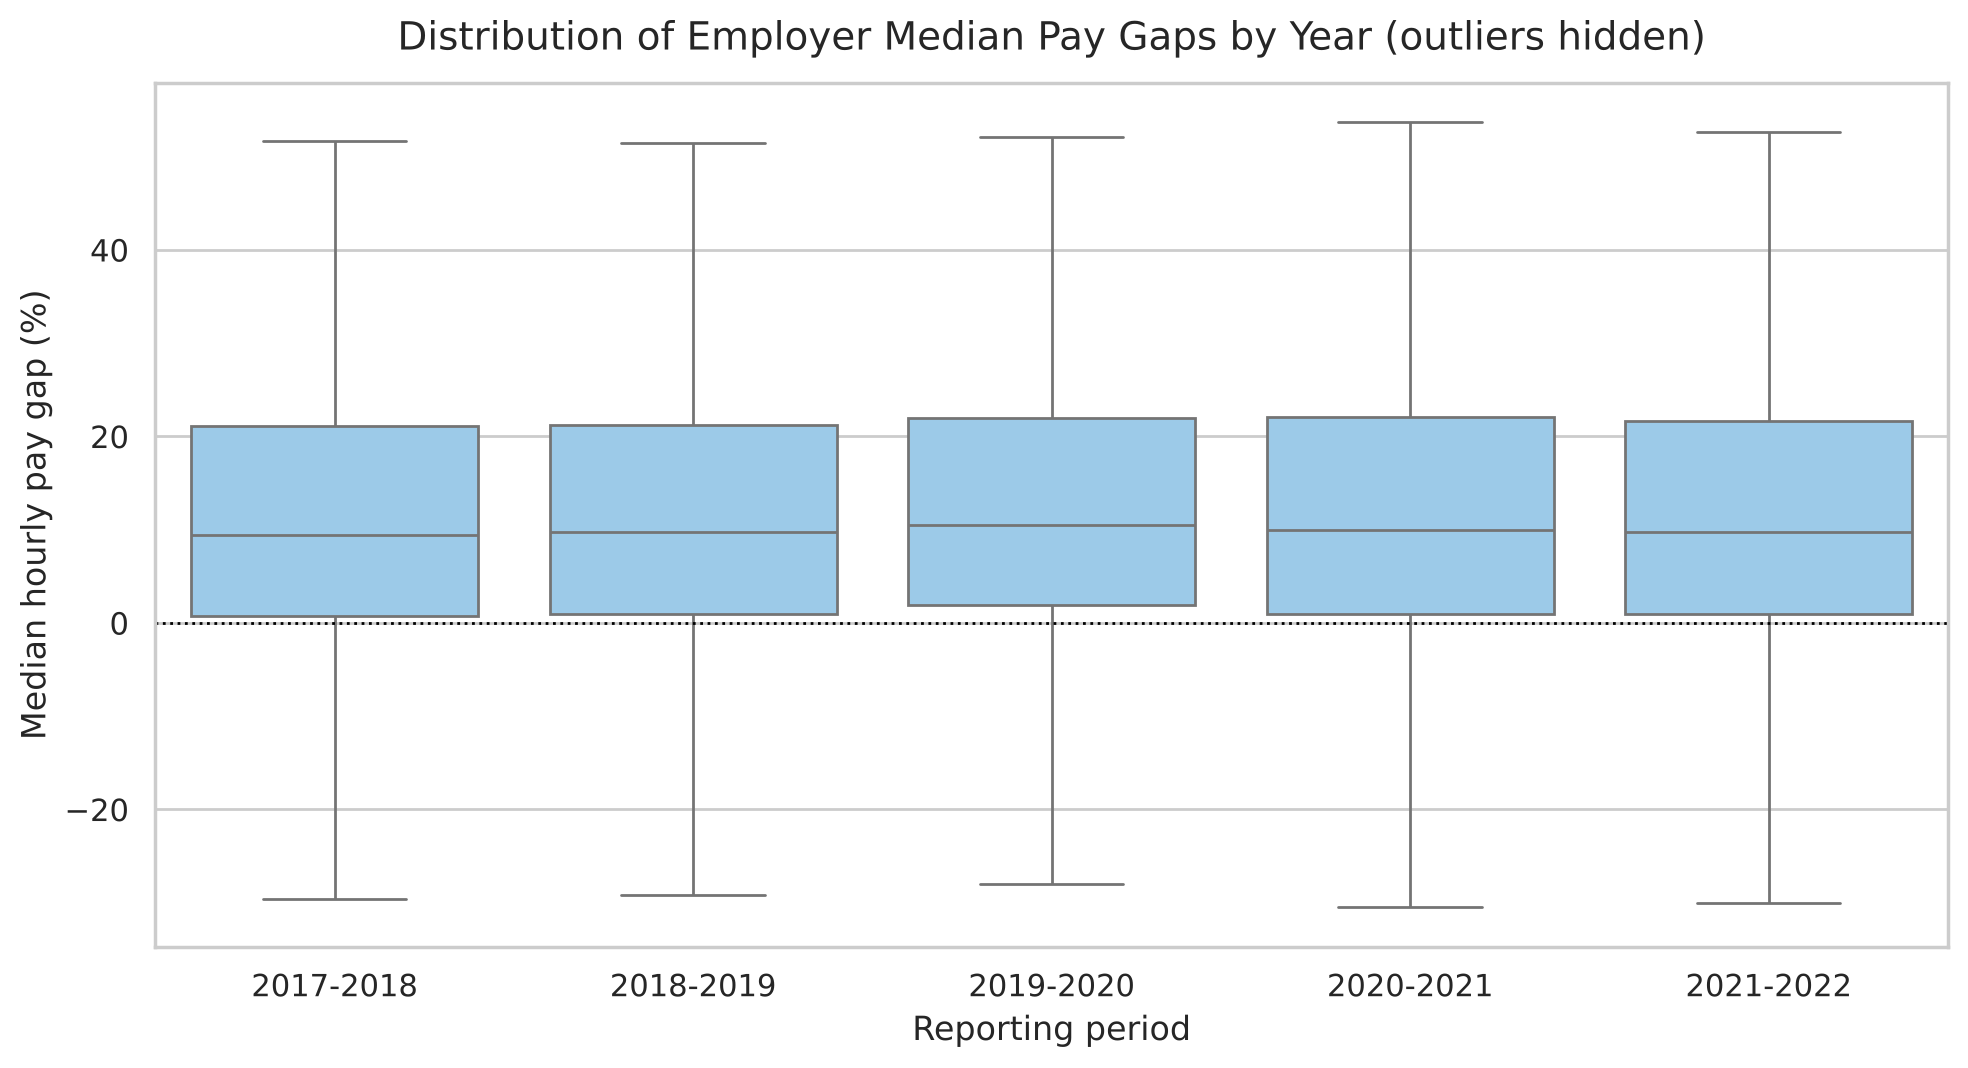

In [7]:
# Show the spread, not just the middle
fig, ax = plt.subplots(figsize=(10, 5.5))
order = sorted(df_years["ReportingPeriod"].unique())
sns.boxplot(data=df_years, x="ReportingPeriod", y=target,
            order=order, showfliers=False, color="#90cdf4", ax=ax)
ax.axhline(0, color="black", linewidth=1, linestyle=":")
ax.set_title("Distribution of Employer Median Pay Gaps by Year (outliers hidden)", fontsize=14, pad=12)
ax.set_xlabel("Reporting period")
ax.set_ylabel("Median hourly pay gap (%)")
plt.tight_layout()
plt.show()

In [8]:
# Did the mix of employers change? Share of each employer size per year
df_years.groupby("ReportingPeriod")["EmployerSize"].value_counts(normalize=True).unstack().round(3)

EmployerSize,1000 to 4999,"20,000 or more",250 to 499,500 to 999,"5000 to 19,999",Less than 250,Not Provided
ReportingPeriod,,,,,,,
2017-2018,0.208,0.006,0.455,0.241,0.042,0.027,0.021
2018-2019,0.213,0.006,0.452,0.248,0.046,0.035,0.001
2019-2020,0.238,0.008,0.410,0.248,0.055,0.034,0.006
2020-2021,0.208,0.006,0.432,0.240,0.044,0.044,0.026
2021-2022,0.208,0.006,0.423,0.245,0.045,0.053,0.020


In [9]:
# Share of each industry per year
df_years.groupby("ReportingPeriod")["Industry"].value_counts(normalize=True).unstack().round(3).T

ReportingPeriod,2017-2018,2018-2019,2019-2020,2020-2021,2021-2022
Industry,,,,,
Accommodation/Food_Service,0.051,0.051,0.033,0.050,0.046
AdministrativeServices,0.113,0.115,0.104,0.109,0.109
Agriculture,0.005,0.005,0.006,0.005,0.005
Arts/Entertainment,0.027,0.027,0.023,0.023,0.021
Communications/Information,0.041,0.043,0.045,0.045,0.048
Education,0.105,0.110,0.131,0.118,0.118
ExtraterritorialOrgs,0.001,0.001,0.000,0.001,0.000
Finance/Insurance,0.038,0.038,0.047,0.042,0.042
Health/SocialWork,0.081,0.087,0.084,0.088,0.089


In [10]:
# Reporting quirks: late filings and missing values per year
print("Share submitted late:")
print(df_years.groupby("ReportingPeriod")["SubmittedAfterTheDeadline"].mean().round(3))

missing = df_years.isna().groupby(df_years["ReportingPeriod"]).mean().round(3)
missing.loc[:, missing.max() > 0]   # only columns with any missing values

Share submitted late:
ReportingPeriod
2017-2018    0.083
2018-2019    0.050
2019-2020    0.000
2020-2021    0.095
2021-2022    0.058
Name: SubmittedAfterTheDeadline, dtype: float64


,Address,PostCode,PostCodeAbbrv,CompanyNumber,SicCodes,Cleaned SIC,DiffMeanBonusPercent,DiffMedianBonusPercent,MaleLowerQuartile,FemaleLowerQuartile,MaleLowerMiddleQuartile,FemaleLowerMiddleQuartile,MaleUpperMiddleQuartile,FemaleUpperMiddleQuartile,MaleTopQuartile,FemaleTopQuartile,CompanyLinkToGPGInfo,ResponsiblePerson
ReportingPeriod,,,,,,,,,,,,,,,,,,
2017-2018,0.000,0.003,0.003,0.126,0.055,0.055,0.003,0.003,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.260,0.157
2018-2019,0.000,0.003,0.003,0.122,0.048,0.048,0.162,0.162,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.309,0.155
2019-2020,0.000,0.003,0.003,0.153,0.063,0.063,0.248,0.249,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.325,0.198
2020-2021,0.001,0.004,0.004,0.128,0.063,0.063,0.251,0.251,0.019,0.019,0.019,0.019,0.019,0.019,0.019,0.019,0.337,0.170
2021-2022,0.002,0.004,0.004,0.134,0.070,0.070,0.267,0.267,0.018,0.018,0.018,0.018,0.018,0.018,0.018,0.018,0.349,0.177


### What the checks show

- **Middle:** yearly medians stay between about 9.4% and 10.5%.
- **Spread:** the box plots overlap almost completely.
- **Mix of employers:** the shares of each size band and industry are nearly identical across years, apart from a small shift in 2019-2020 (see below).

The distribution of the median hourly gap and the mix of reporting employers were stable across 2017–2021, so we do not expect the reporting year to bias a model of the median hourly gap.

**Exceptions to keep in mind:**
- **Bonus columns:** the bonus gap is missing in almost no 2017-2018 rows but in roughly 16–27% of rows in later years, so the bonus columns are *not* comparable across years without handling those missing values.
- **2019-2020:** about 3,500 fewer reports than other years because enforcement was paused during COVID-19. The mix shifted slightly that year: smaller employers (250 to 499 staff) fell from about 45% to 41% of reports, and accommodation/food service from about 5% to 3%, likely because sectors hit hardest by the pandemic used the pause. The pay gap itself still looks similar to other years.

## 4. PCA: what are the main ways employers differ?

**Question:** across all the pay-gap measures at once, what are the main ways UK employers differ from each other, and where do industries sit on those axes? For a certification body, this shows whether "has a pay gap" is one thing, or several different patterns that need different conversations with lagging companies.

**Data choices**
- **Most recent full year only (2021-2022).** That's the filing a certification decision for next year would be based on, and it means each employer appears once.
- **10 numeric inputs:** mean and median hourly gap, mean and median bonus gap, share of men and of women getting a bonus, and the share of women in each pay quartile. The male quartile columns are left out because each one is just 100 minus the female share.
- **Missing bonus gaps (about 27% of rows):** in 95% of these rows, no men received a bonus, so there is no bonus gap to measure. We fill them with 0 rather than dropping a quarter of the employers.
- **Extreme bonus gaps:** a bonus gap can't be above 100% but can be hugely negative (a few employers report below −1,000%). We cap the bonus gaps at −100% (women's bonus twice men's) so a handful of firms don't dominate the components; about 2–3% of rows are affected.
- **Missing quartile shares (192 rows, under 2%):** dropped.
- **Standardized** before PCA, because the inputs are on different scales and the bonus gaps vary far more than the rest.

In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

pca_cols = ["DiffMeanHourlyPercent", "DiffMedianHourlyPercent",
            "DiffMeanBonusPercent", "DiffMedianBonusPercent",
            "MaleBonusPercent", "FemaleBonusPercent",
            "FemaleLowerQuartile", "FemaleLowerMiddleQuartile",
            "FemaleUpperMiddleQuartile", "FemaleTopQuartile"]

latest = df[df["ReportingPeriod"] == "2021-2022"].copy()
print("Missing values before cleaning:")
print(latest[pca_cols].isna().sum())

# No bonus paid -> no bonus gap: fill with 0, then cap extreme negative gaps at -100%
for col in ["DiffMeanBonusPercent", "DiffMedianBonusPercent"]:
    latest[col] = latest[col].fillna(0).clip(lower=-100)

# Drop the few employers missing their quartile shares
latest = latest.dropna(subset=pca_cols).reset_index(drop=True)
print(len(latest), "employers used in the PCA")

Missing values before cleaning:
DiffMeanHourlyPercent           0
DiffMedianHourlyPercent         0
DiffMeanBonusPercent         2785
DiffMedianBonusPercent       2785
MaleBonusPercent                0
FemaleBonusPercent              0
FemaleLowerQuartile           192
FemaleLowerMiddleQuartile     192
FemaleUpperMiddleQuartile     192
FemaleTopQuartile             192
dtype: int64
10233 employers used in the PCA


In [12]:
# Standardize (mean 0, standard deviation 1), then run PCA on all 10 inputs
scaler = StandardScaler()
scaled_df = pd.DataFrame(scaler.fit_transform(latest[pca_cols]), columns=pca_cols)

pcs = PCA()
pc_names = ["PC" + str(i + 1) for i in range(len(pca_cols))]
scores_df = pd.DataFrame(pcs.fit_transform(scaled_df), columns=pc_names)

# Importance of each component
summary_df = pd.DataFrame({
    "Eigenvalue": pcs.explained_variance_,
    "% of variance": pcs.explained_variance_ratio_ * 100,
    "Cumulative %": np.cumsum(pcs.explained_variance_ratio_) * 100,
}, index=pc_names)
summary_df.round(2)

,Eigenvalue,% of variance,Cumulative %
PC1,4.07,40.72,40.72
PC2,2.34,23.41,64.13
PC3,1.38,13.83,77.96
PC4,1.15,11.47,89.43
PC5,0.42,4.20,93.63
PC6,0.29,2.88,96.51
PC7,0.13,1.33,97.83
PC8,0.10,1.02,98.85
PC9,0.07,0.71,99.56
PC10,0.04,0.44,100.00


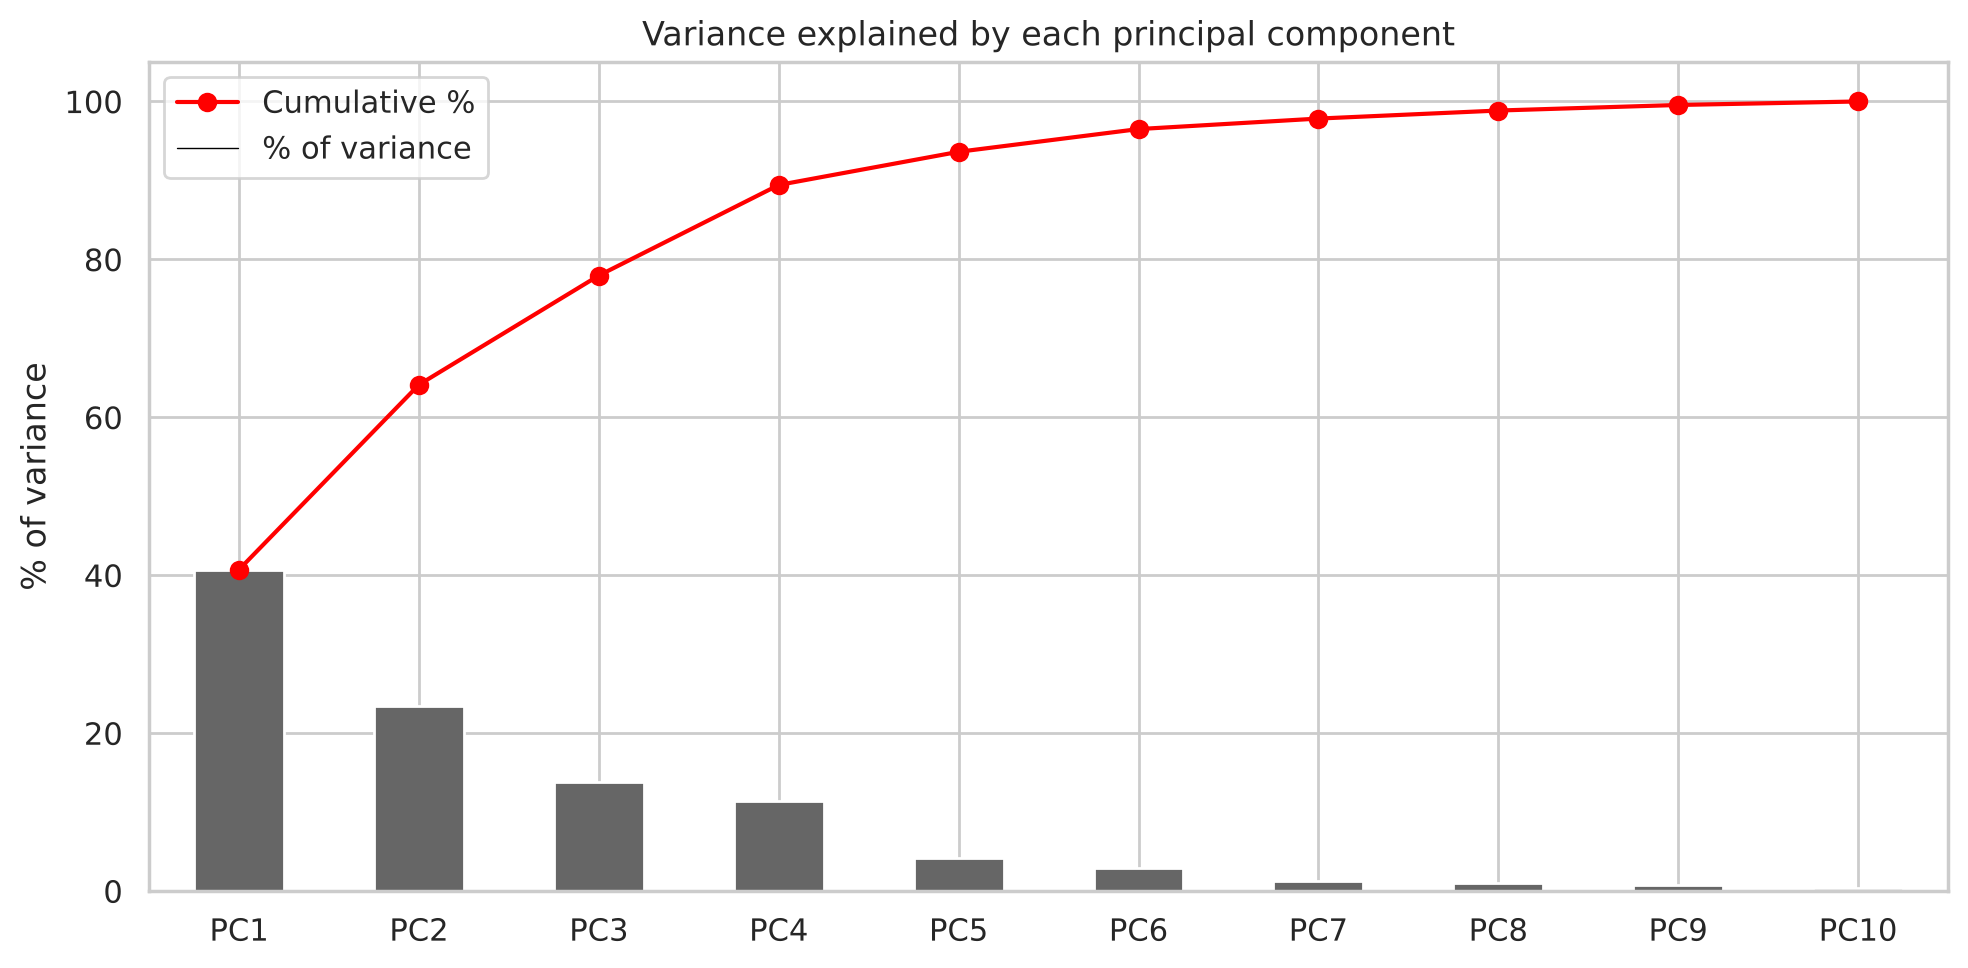

In [13]:
# Bars per component, line for the running total
ax = summary_df["% of variance"].plot.bar(figsize=(10, 5), color="0.4")
summary_df["Cumulative %"].plot(marker="o", color="red", ax=ax)
ax.axhline(0, color="black", linewidth=0.5)
ax.set_ylabel("% of variance")
ax.set_title("Variance explained by each principal component")
ax.legend(["Cumulative %", "% of variance"])
plt.tight_layout()
plt.show()

In [14]:
# Eigenvalue of each component
print(summary_df["Eigenvalue"].round(2).to_string())
print("Sum of eigenvalues:", round(summary_df["Eigenvalue"].sum(), 2))

PC1     4.07
PC2     2.34
PC3     1.38
PC4     1.15
PC5     0.42
PC6     0.29
PC7     0.13
PC8     0.10
PC9     0.07
PC10    0.04
Sum of eigenvalues: 10.0


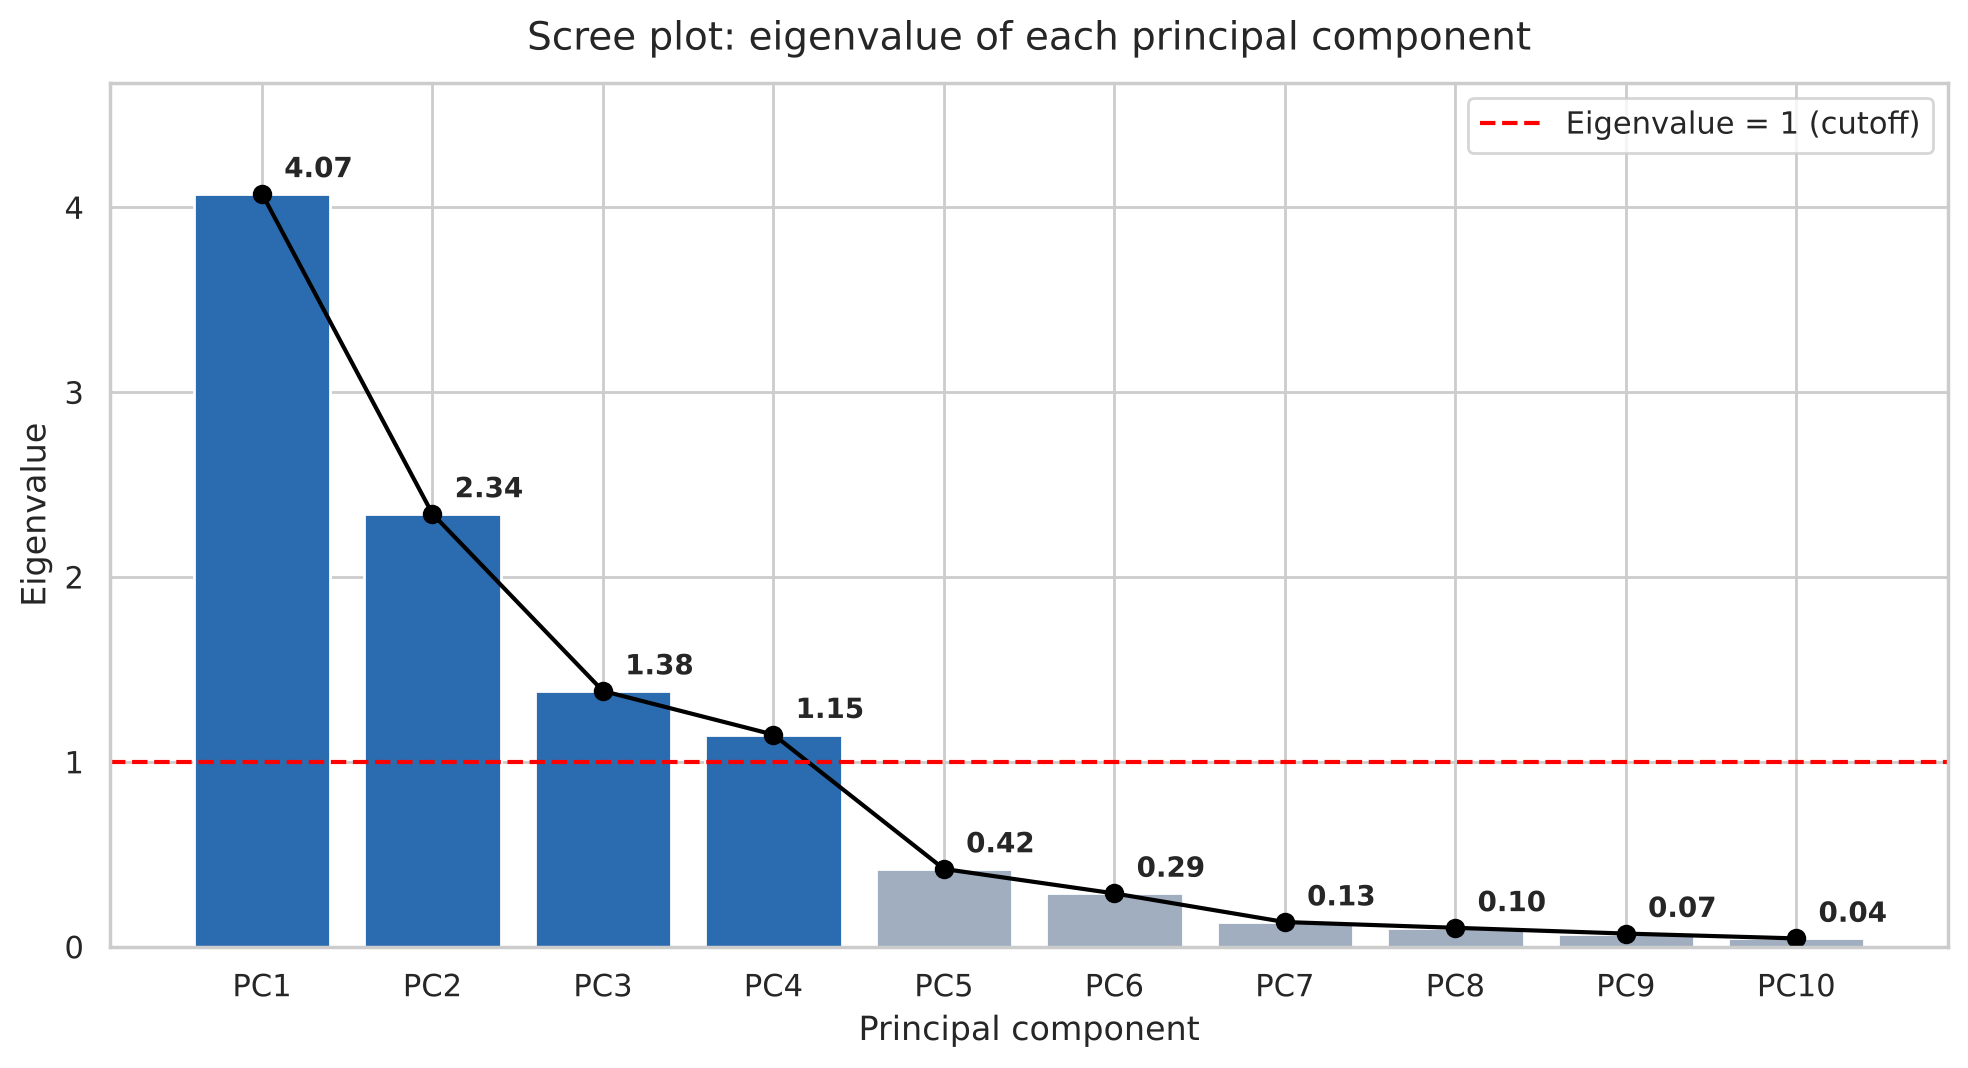

In [15]:
# Scree plot: eigenvalue of each component, with the cutoff at 1 (latent root criterion)
fig, ax = plt.subplots(figsize=(10, 5.5))
colors = ["#2b6cb0" if e > 1 else "#a0aec0" for e in summary_df["Eigenvalue"]]
ax.bar(summary_df.index, summary_df["Eigenvalue"], color=colors)
ax.plot(summary_df.index, summary_df["Eigenvalue"], marker="o", color="black", linewidth=1.5)
ax.axhline(1, color="red", linestyle="--", linewidth=1.5, label="Eigenvalue = 1 (cutoff)")

for x, y in zip(summary_df.index, summary_df["Eigenvalue"]):
    ax.annotate(f"{y:.2f}", (x, y), textcoords="offset points", xytext=(8, 6),
                ha="left", fontsize=10, fontweight="bold")

ax.set_xlabel("Principal component")
ax.set_ylabel("Eigenvalue")
ax.set_title("Scree plot: eigenvalue of each principal component", fontsize=14, pad=12)
ax.set_ylim(0, summary_df["Eigenvalue"].max() + 0.6)
ax.legend()
plt.tight_layout()
plt.show()

**Reading the eigenvalues:** the inputs are standardized, so each of the 10 columns contributes 1 unit of variance and the eigenvalues add up to about 10. An eigenvalue above 1 means the component carries more information than any single original column.

**How many components to keep:** by the latent root criterion (keep components with an eigenvalue above 1), we keep **4 components**: PC1 (4.07), PC2 (2.34), PC3 (1.38) and PC4 (1.15). Together they carry about **89%** of the variation in the 10 inputs. After PC4 the eigenvalue drops sharply to 0.42, so the remaining six components add little.

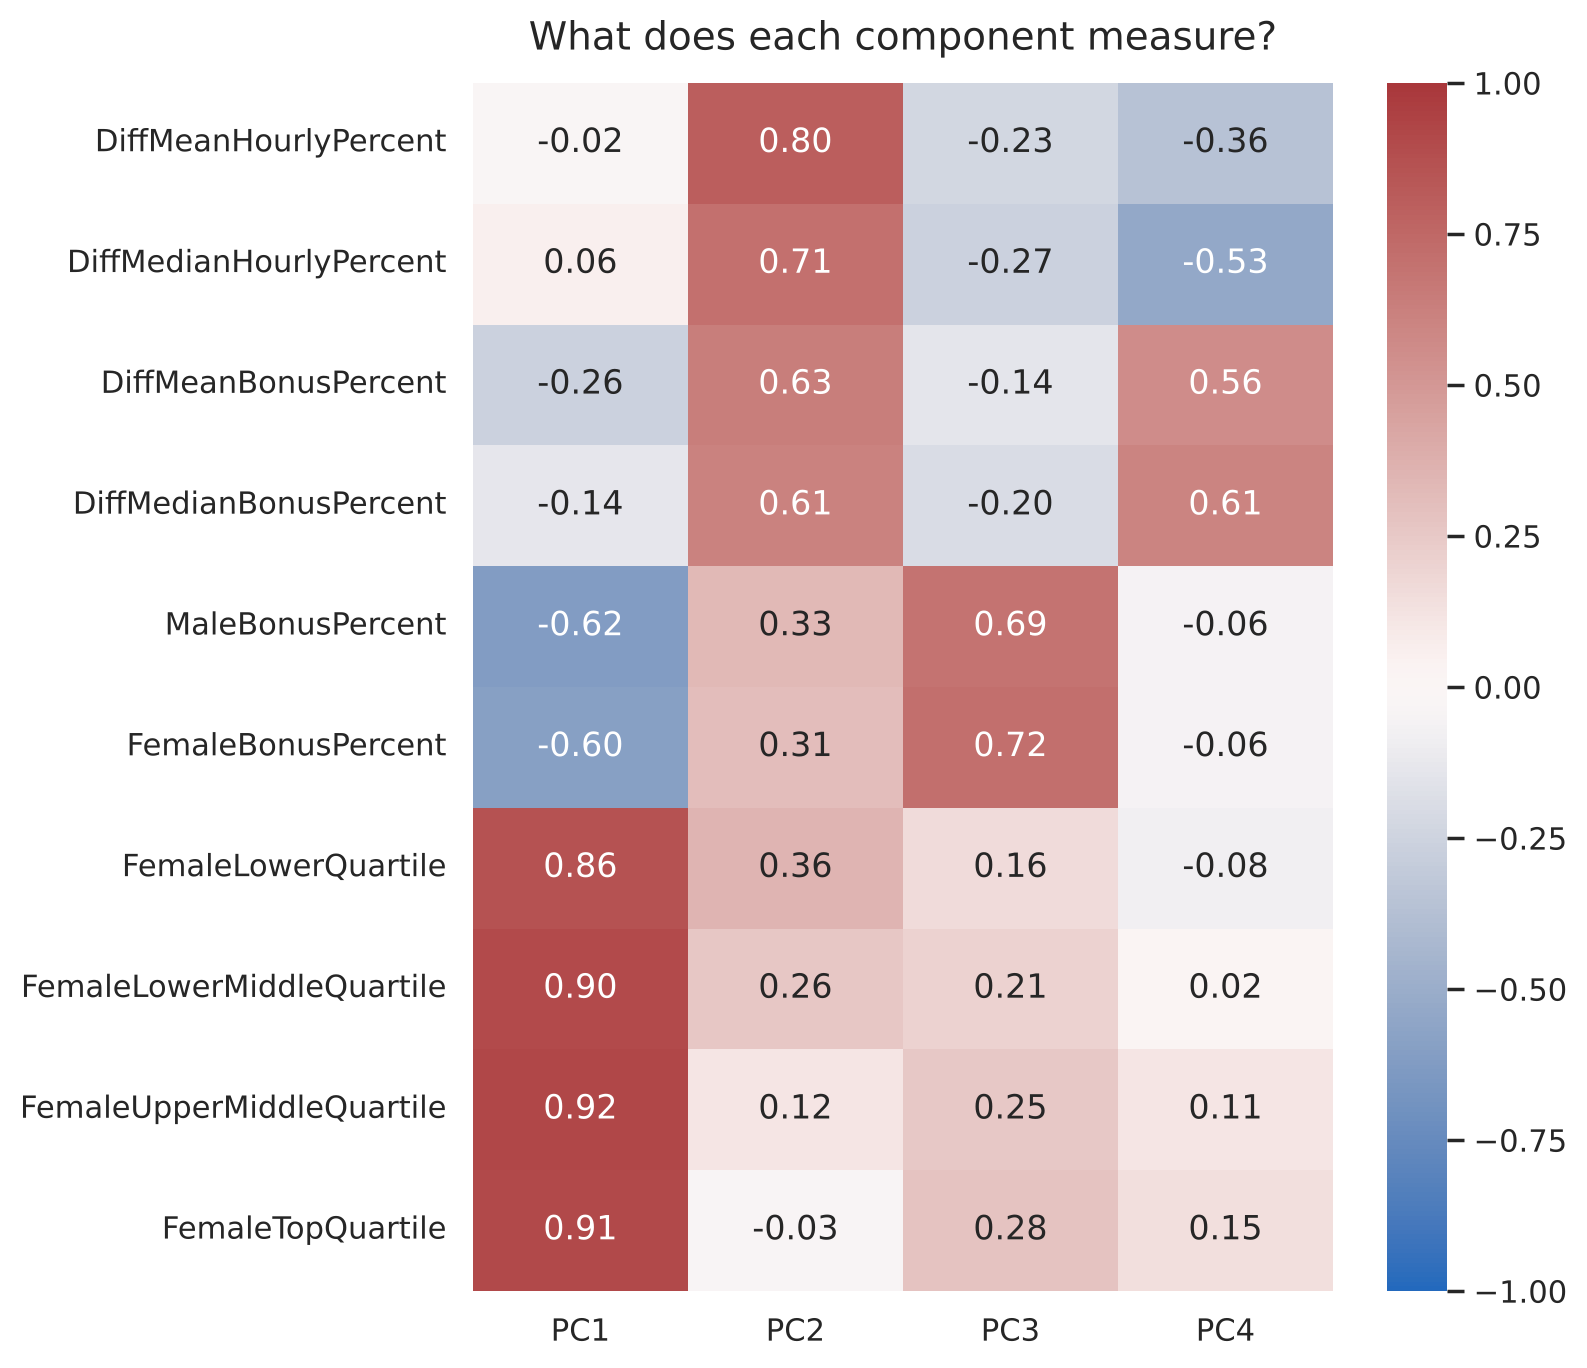

In [16]:
# Component matrix: correlation of each input with each kept component
loadings_df = pd.concat([scores_df, scaled_df], axis=1).corr().loc[pca_cols, pc_names[:4]]

fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(loadings_df, annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="vlag", ax=ax)
ax.grid(False)
ax.set_title("What does each component measure?", fontsize=14, pad=12)
plt.tight_layout()
plt.show()

### What the components measure

(The sign of a component is arbitrary; what matters is which inputs move together.)

- **PC1, women's share of the workforce (41% of variance).** High scores mean women make up a large share of every pay quartile; these employers also tend to pay bonuses to fewer staff. PC1 barely relates to the pay gap itself (correlations of −0.02 and 0.06 with the hourly gaps).
- **PC2, size of the pay gap (23%).** High scores mean large hourly *and* bonus gaps in men's favour, along with a lower share of women in the top quartile than in the bottom one.
- **PC3, bonus culture (14%).** High scores mean a large share of both men and women receive bonuses.
- **PC4, bonus gap vs. hourly gap (11%).** Separates employers whose gap shows up mainly in bonuses (high) from those whose gap shows up mainly in hourly pay (low).

**Key point:** how many women an employer has (PC1) and how big its pay gap is (PC2) are *separate* dimensions. Having a mostly female workforce does not mean a small gap.

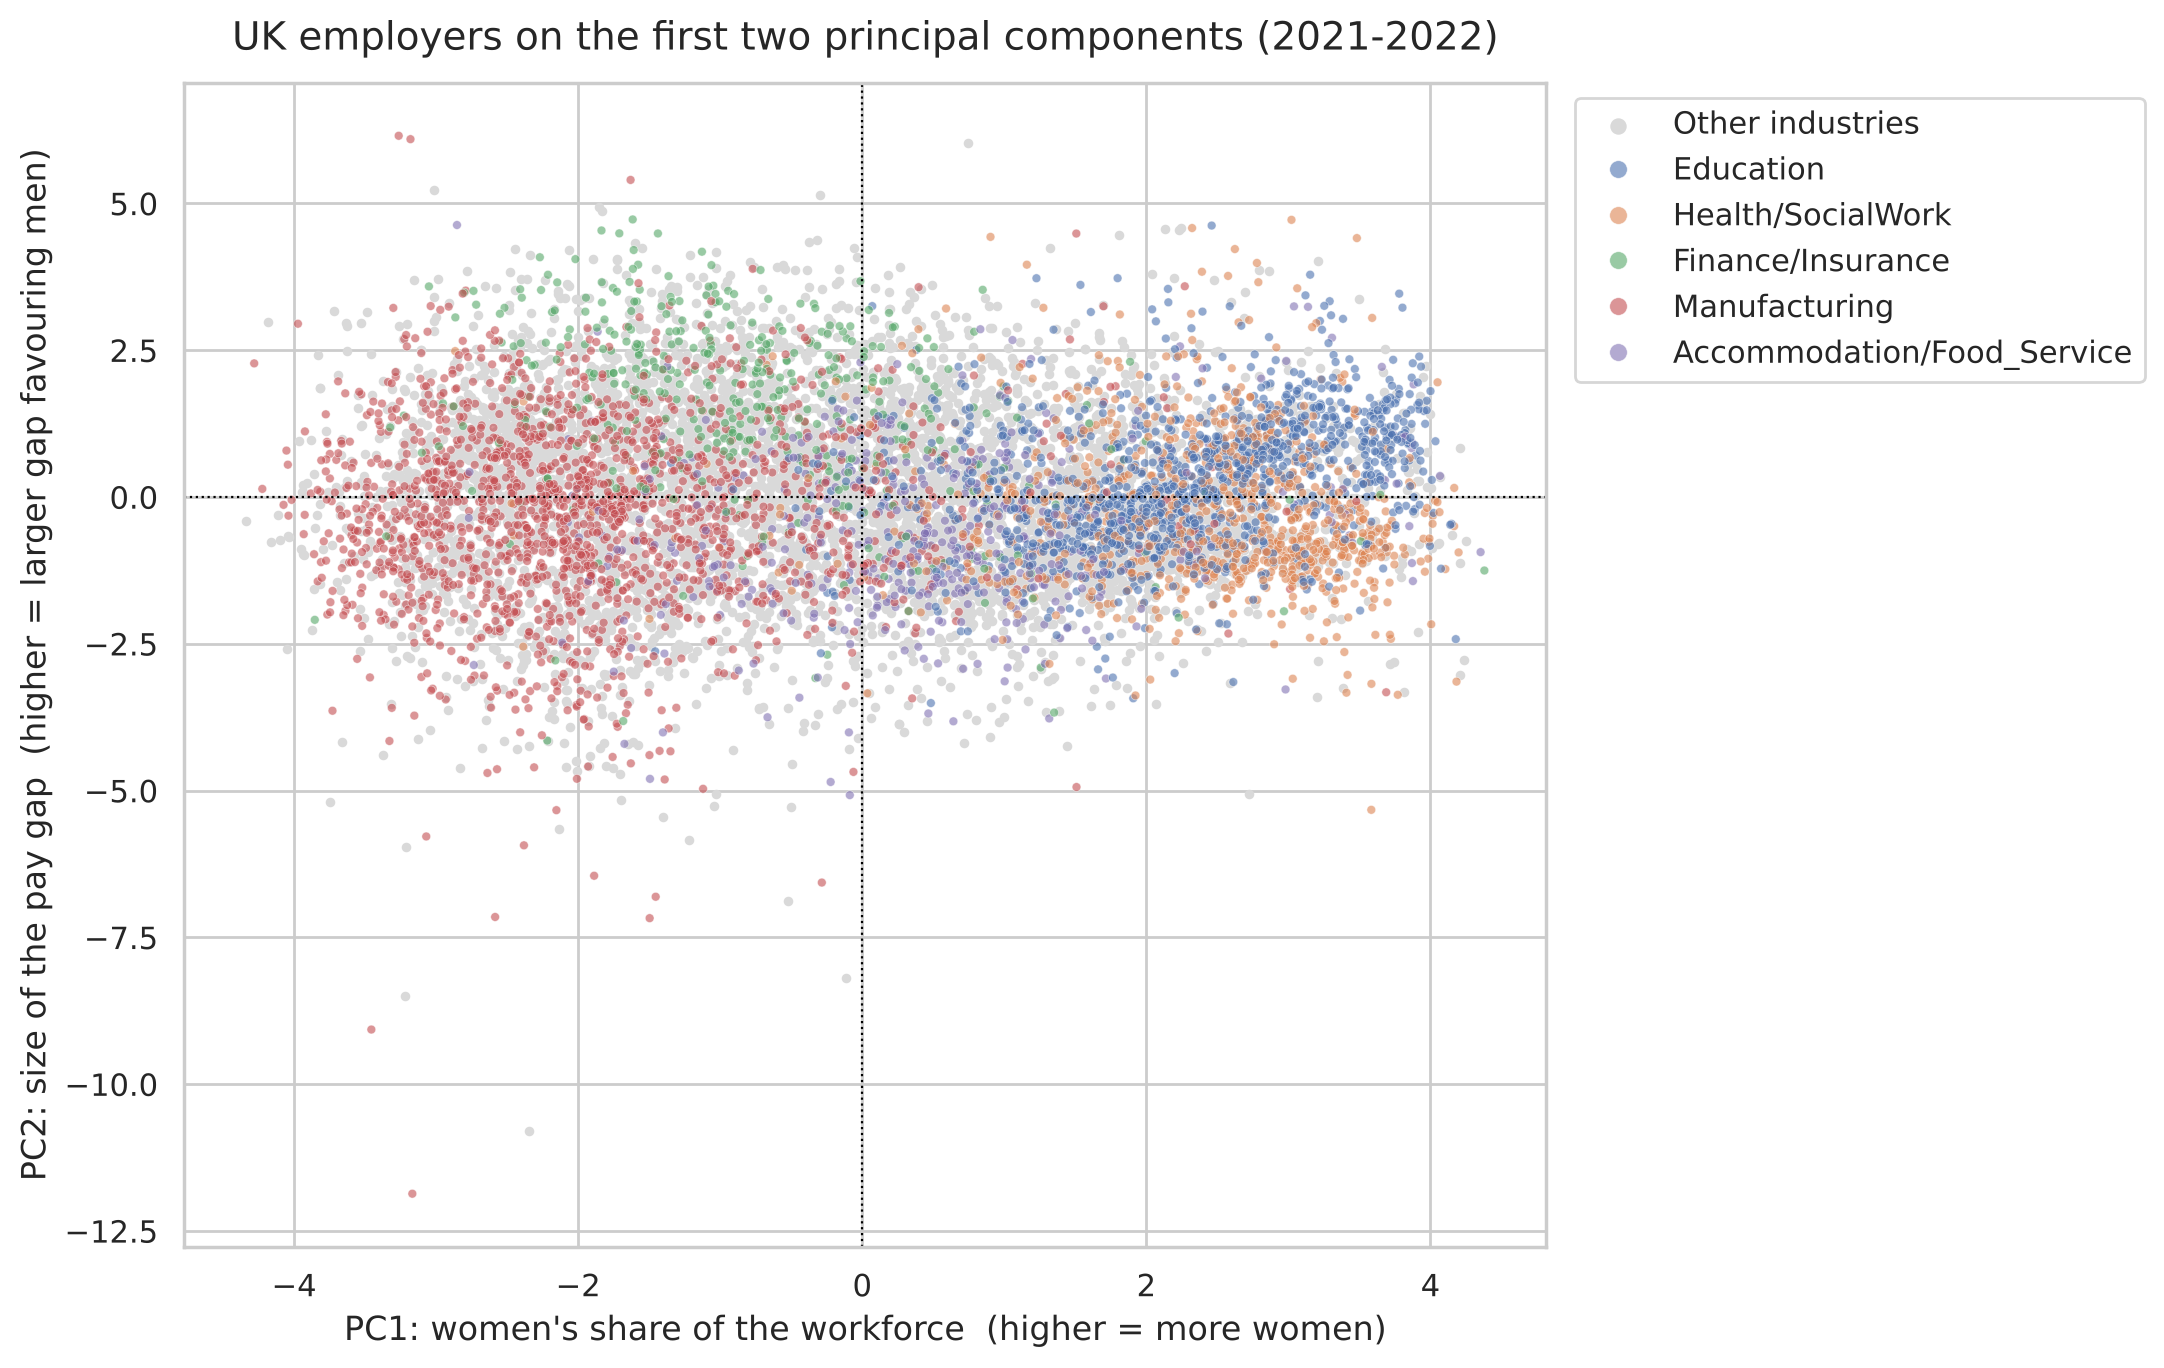

In [17]:
# Employers on the first two components, highlighting five contrasting industries
plot_df = pd.concat([latest[["Industry", "EmployerSize"]], scores_df[pc_names[:4]]], axis=1)
highlight = ["Education", "Health/SocialWork", "Finance/Insurance",
             "Manufacturing", "Accommodation/Food_Service"]

fig, ax = plt.subplots(figsize=(11, 7))
others = plot_df[~plot_df["Industry"].isin(highlight)]
ax.scatter(others["PC1"], others["PC2"], s=6, color="0.85", label="Other industries")
sns.scatterplot(data=plot_df[plot_df["Industry"].isin(highlight)], x="PC1", y="PC2",
                hue="Industry", hue_order=highlight, s=10, alpha=0.6, ax=ax)
ax.axhline(0, color="black", linewidth=0.8, linestyle=":")
ax.axvline(0, color="black", linewidth=0.8, linestyle=":")
ax.set_xlabel("PC1: women's share of the workforce  (higher = more women)")
ax.set_ylabel("PC2: size of the pay gap  (higher = larger gap favouring men)")
ax.set_title("UK employers on the first two principal components (2021-2022)", fontsize=14, pad=12)
ax.legend(markerscale=2, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

In [18]:
# Average position of each industry on the kept components,
# alongside its median hourly gap for reference
industry_pcs = (plot_df.join(latest["DiffMedianHourlyPercent"])
                .groupby("Industry")
                .agg(employers=("PC1", "size"), PC1=("PC1", "mean"), PC2=("PC2", "mean"),
                     PC3=("PC3", "mean"), PC4=("PC4", "mean"),
                     median_gap=("DiffMedianHourlyPercent", "median"))
                .sort_values("PC2", ascending=False))
industry_pcs.round(2)

,employers,PC1,PC2,PC3,PC4,median_gap
Industry,,,,,,
Finance/Insurance,436,-0.78,1.52,0.32,-0.11,23.00
Scientific/Technical,698,-0.50,0.59,0.14,0.00,15.15
Communications/Information,496,-1.35,0.54,0.05,-0.10,16.75
Unknown,804,0.97,0.34,0.20,-0.17,14.80
Education,1217,2.26,0.26,-0.35,-0.45,21.40
Real Estate,118,0.00,0.26,0.06,0.04,9.10
Wholesale & Retail Trade,904,-0.79,0.19,0.48,0.20,6.10
Mining/Quarrying,50,-2.44,0.07,-0.47,-0.70,20.45
Arts/Entertainment,210,-0.19,-0.03,-0.79,0.20,5.40


### Takeaways for certification

- **The pay gap is its own dimension.** PC2 captures the gap across hourly and bonus pay together, and it is mostly separate from workforce make-up (PC1). A score along PC2 is a better single summary of an employer's gap than any one column, which makes it a candidate input for flagging lagging companies.
- **Industries split into different kinds of problem:**
  - **Finance/Insurance** sits highest on PC2: the largest combined hourly and bonus gaps.
  - **Education** has one of the most female workforces (high PC1) *and* one of the largest median hourly gaps (about 21%). Women are concentrated in the lower pay quartiles, so the issue is progression, not hiring.
  - **Health/Social Work** is similarly female-heavy but has a very small median gap (about 2%).
  - **Manufacturing, Mining and Transport** are male-heavy (low PC1); their gaps vary.
- **Different patterns need different notices.** A lagging firm with a hiring-mix problem (low PC1) needs a different message from one with a progression problem (high PC1, high PC2), or one whose gap is mainly in bonuses (high PC4).

**Note:** this PCA is descriptive and is fit on all 2021-2022 employers. If PCA components are later used as inputs to a predictive model, the scaler and PCA must be fit on the training data only.

## 5. kNN: how well does each input predict the pay gap?

**Question:** using only facts *about* an employer (not its gap figures), how well can kNN predict its median hourly pay gap, and which inputs carry the most information?

**Setup**
- **Target:** `DiffMedianHourlyPercent` for 2021-2022 (the same employers as the PCA).
- **Inputs:** the share of women in each pay quartile, the share of men and of women getting a bonus, industry, and employer size. The other gap columns (mean hourly gap and the bonus gaps) are left out: they are different measures of the same gap, so predicting the gap from them would be circular.
- **Model:** kNN regression (`KNeighborsRegressor`, the regression version of the course's `KNeighborsClassifier`) after standardizing, as kNN works on distances.
- **Split:** 70% train / 30% test. All tuning and input comparisons use 5-fold cross-validation on the training set only; the test set is used once at the end.
- **Metric:** R² (share of the variation in the gap the model explains; 0 = no better than predicting the average, negative = worse than the average). MAE (average error in percentage points) is reported on the test set.

In [19]:
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score
from sklearn.dummy import DummyRegressor
from sklearn.metrics import r2_score, mean_absolute_error

knn_num = ["FemaleLowerQuartile", "FemaleLowerMiddleQuartile",
           "FemaleUpperMiddleQuartile", "FemaleTopQuartile",
           "MaleBonusPercent", "FemaleBonusPercent"]
knn_cat = ["Industry", "EmployerSize"]
knn_target = "DiffMedianHourlyPercent"

knn_df = df[df["ReportingPeriod"] == "2021-2022"].dropna(subset=knn_num + knn_cat + [knn_target])

# One-hot encode industry and size
X = pd.get_dummies(knn_df[knn_num + knn_cat], columns=knn_cat, dtype=int)
y = knn_df[knn_target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1)
folds = KFold(n_splits=5, shuffle=True, random_state=1)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (7163, 32)  Test: (3070, 32)


### 5.1 Tune kNN on all inputs
Two hyperparameters: the number of neighbours `k`, and whether all neighbours count equally (`uniform`) or closer ones count more (`distance`).

Best settings: {'kneighborsregressor__n_neighbors': 7, 'kneighborsregressor__weights': 'distance'}
Cross-validated R²: 0.412


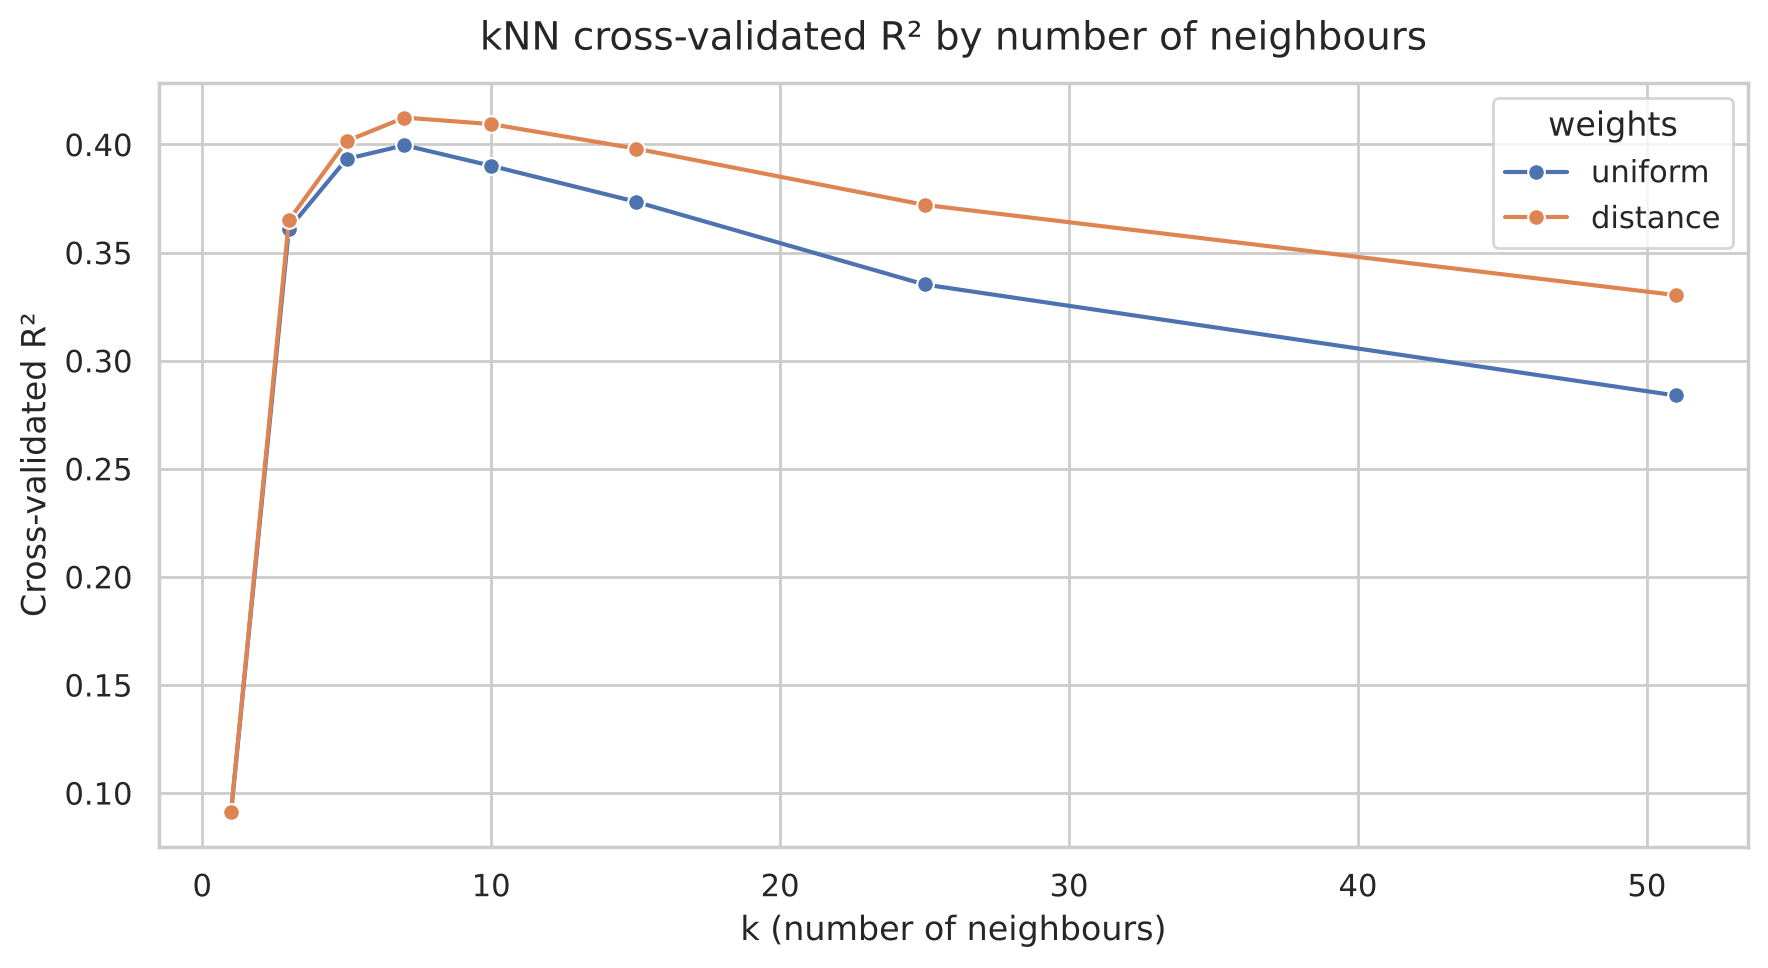

In [20]:
param_grid = {"kneighborsregressor__n_neighbors": [1, 3, 5, 7, 10, 15, 25, 51],
              "kneighborsregressor__weights": ["uniform", "distance"]}

grid = GridSearchCV(make_pipeline(StandardScaler(), KNeighborsRegressor()),
                    param_grid, scoring="r2", cv=folds)
grid.fit(X_train, y_train)

best_k = grid.best_params_["kneighborsregressor__n_neighbors"]
best_w = grid.best_params_["kneighborsregressor__weights"]
print("Best settings:", grid.best_params_)
print("Cross-validated R²:", round(grid.best_score_, 3))

# Cross-validated R² for every k, for both weighting options
cv_res = pd.DataFrame(grid.cv_results_)
cv_res["k"] = cv_res["param_kneighborsregressor__n_neighbors"]
cv_res["weights"] = cv_res["param_kneighborsregressor__weights"]

fig, ax = plt.subplots(figsize=(9, 5))
sns.lineplot(data=cv_res, x="k", y="mean_test_score", hue="weights", marker="o", ax=ax)
ax.set_title("kNN cross-validated R² by number of neighbours", fontsize=14, pad=12)
ax.set_xlabel("k (number of neighbours)")
ax.set_ylabel("Cross-validated R²")
plt.tight_layout()
plt.show()

### 5.2 The input loop
For each input, two checks with the tuned settings:
- **Drop it:** cross-validated R² with every input *except* this one. The bigger the loss compared with using all inputs, the more unique information the input carries.
- **Use it alone:** cross-validated R² with *only* this input.

Industry and employer size are treated as one input each (all their dummy columns are dropped or kept together).

In [21]:
def knn_model():
    return make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=best_k, weights=best_w))

# Group the dummy columns back into their original inputs
input_groups = {col: [col] for col in knn_num}
input_groups["Industry"] = [c for c in X.columns if c.startswith("Industry_")]
input_groups["EmployerSize"] = [c for c in X.columns if c.startswith("EmployerSize_")]

all_inputs_r2 = cross_val_score(knn_model(), X_train, y_train, scoring="r2", cv=folds).mean()
print("All inputs, cross-validated R²:", round(all_inputs_r2, 3))

loop_results = []
for name, cols in input_groups.items():
    r2_without = cross_val_score(knn_model(), X_train.drop(columns=cols), y_train, scoring="r2", cv=folds).mean()
    r2_alone = cross_val_score(knn_model(), X_train[cols], y_train, scoring="r2", cv=folds).mean()
    loop_results.append({"input": name,
                         "R² without it": r2_without,
                         "loss when dropped": all_inputs_r2 - r2_without,
                         "R² alone": r2_alone})

loop_df = pd.DataFrame(loop_results).sort_values("loss when dropped", ascending=False).set_index("input")
loop_df.round(3)

All inputs, cross-validated R²: 0.412


,R² without it,loss when dropped,R² alone
input,,,
FemaleLowerQuartile,0.294,0.118,-0.085
FemaleTopQuartile,0.332,0.081,-0.217
FemaleLowerMiddleQuartile,0.392,0.021,-0.202
FemaleUpperMiddleQuartile,0.402,0.011,-0.265
FemaleBonusPercent,0.423,-0.011,-0.212
MaleBonusPercent,0.428,-0.016,-0.294
Industry,0.474,-0.061,0.063
EmployerSize,0.502,-0.090,-0.119


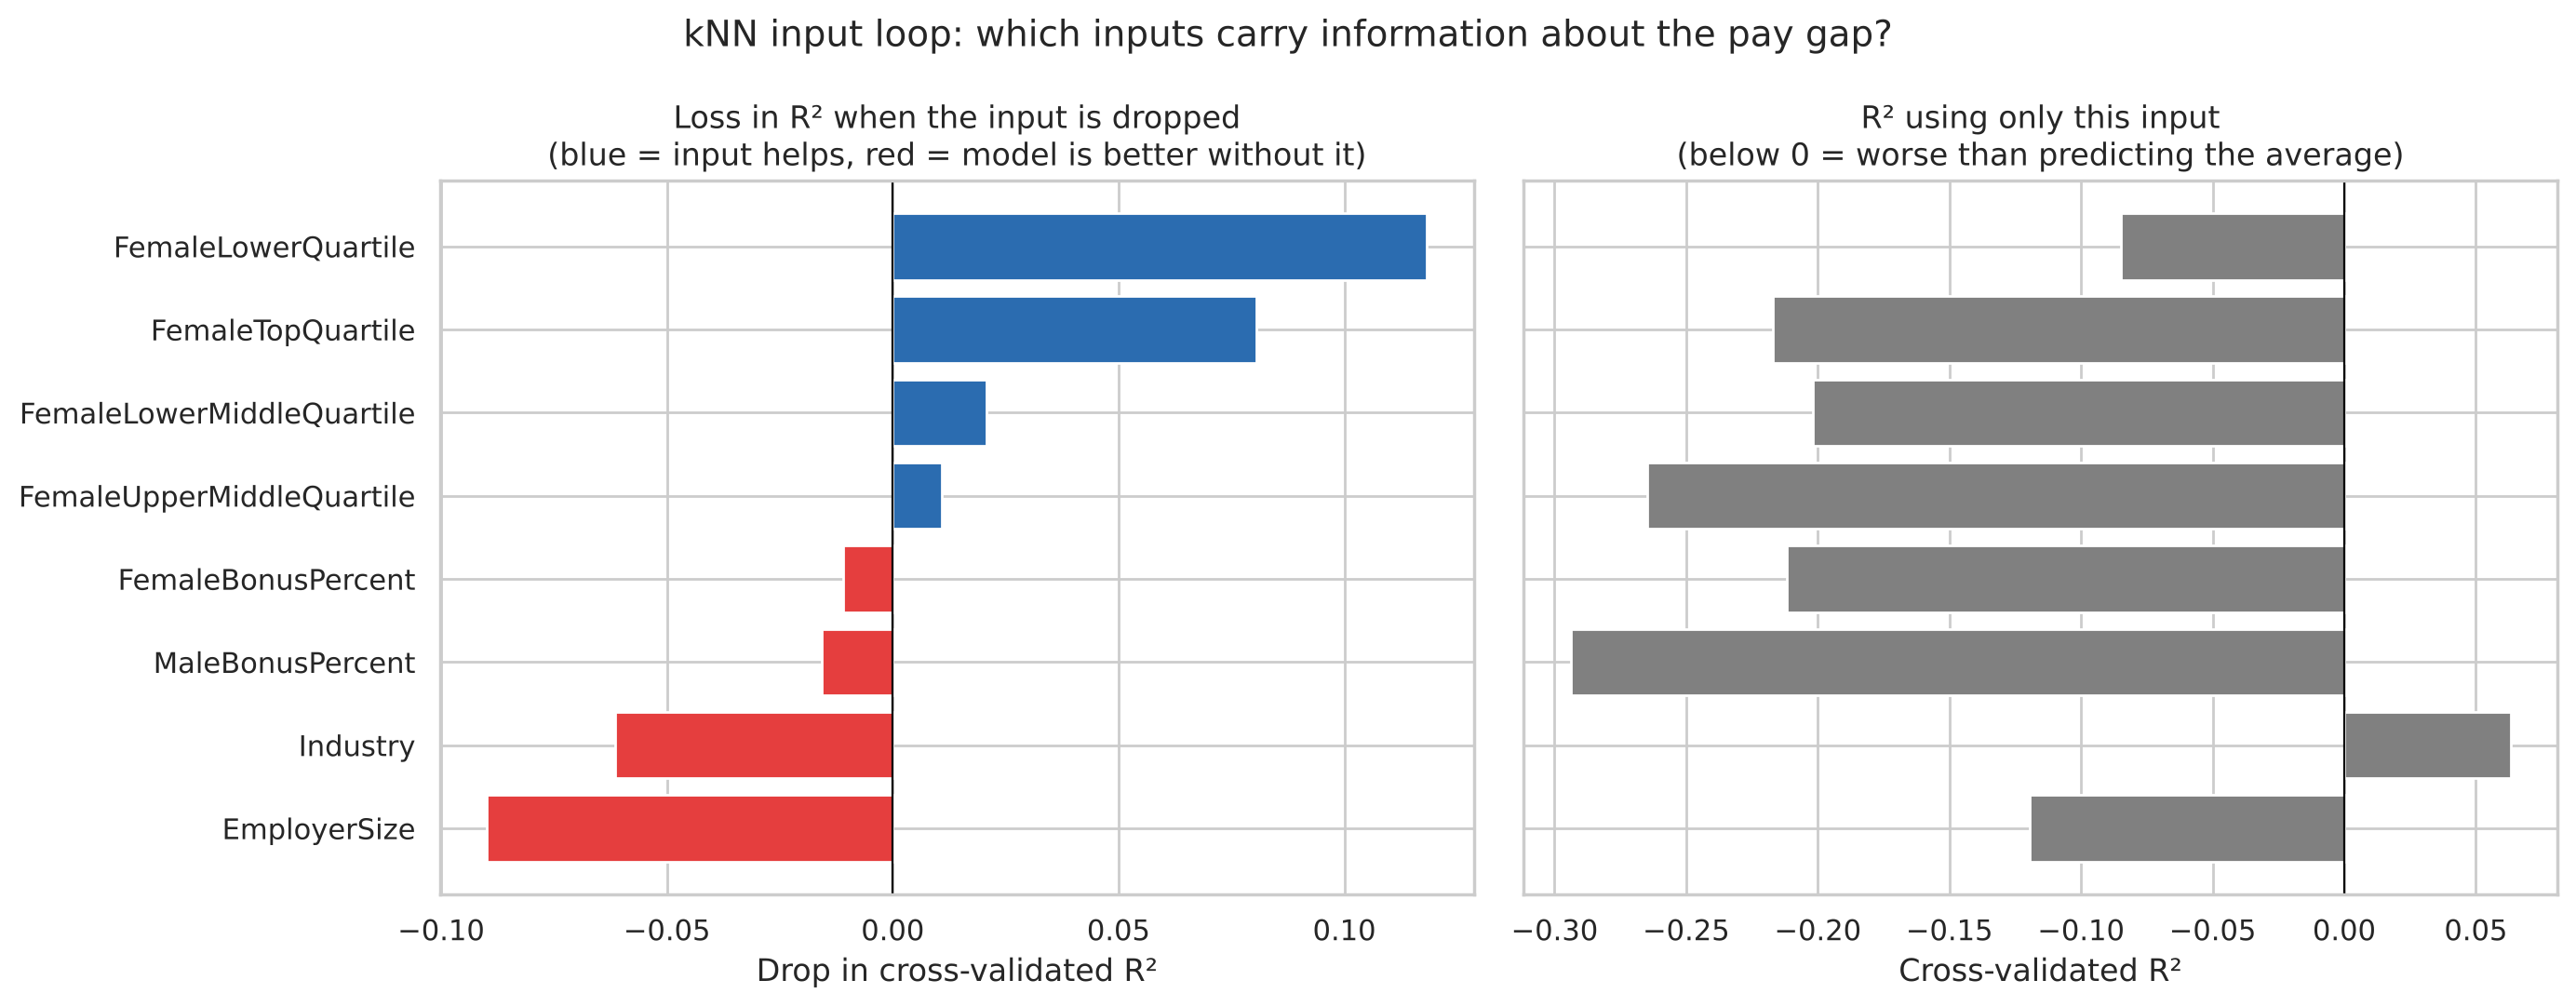

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)

colors = ["#2b6cb0" if v > 0 else "#e53e3e" for v in loop_df["loss when dropped"]]
axes[0].barh(loop_df.index, loop_df["loss when dropped"], color=colors)
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_title("Loss in R² when the input is dropped\n(blue = input helps, red = model is better without it)")
axes[0].set_xlabel("Drop in cross-validated R²")
axes[0].invert_yaxis()

axes[1].barh(loop_df.index, loop_df["R² alone"], color="0.5")
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_title("R² using only this input\n(below 0 = worse than predicting the average)")
axes[1].set_xlabel("Cross-validated R²")

plt.suptitle("kNN input loop: which inputs carry information about the pay gap?", fontsize=14)
plt.tight_layout()
plt.show()

### 5.3 Refit without the inputs that hurt, and evaluate on the test set
Inputs whose removal *raised* cross-validated R² are dropped, then kNN is re-tuned on the remaining inputs. This choice uses the training folds only; the test set is touched once, below.

In [23]:
hurting = loop_df.index[loop_df["loss when dropped"] < 0].tolist()
keep_cols = [c for name, cols in input_groups.items() if name not in hurting for c in cols]
print("Dropped inputs:", hurting)
print("Kept inputs:", [name for name in input_groups if name not in hurting])

grid_reduced = GridSearchCV(make_pipeline(StandardScaler(), KNeighborsRegressor()),
                            param_grid, scoring="r2", cv=folds)
grid_reduced.fit(X_train[keep_cols], y_train)
print("Best settings (reduced inputs):", grid_reduced.best_params_)
print("Cross-validated R² (reduced inputs):", round(grid_reduced.best_score_, 3))

Dropped inputs: ['FemaleBonusPercent', 'MaleBonusPercent', 'Industry', 'EmployerSize']
Kept inputs: ['FemaleLowerQuartile', 'FemaleLowerMiddleQuartile', 'FemaleUpperMiddleQuartile', 'FemaleTopQuartile']


Best settings (reduced inputs): {'kneighborsregressor__n_neighbors': 25, 'kneighborsregressor__weights': 'distance'}
Cross-validated R² (reduced inputs): 0.557


In [24]:
# One-time evaluation on the held-out test set, against a baseline that always predicts the training average
baseline = DummyRegressor(strategy="mean").fit(X_train, y_train)

test_results = pd.DataFrame({
    "Model": ["Baseline (predict the average)", "kNN, all inputs", "kNN, reduced inputs"],
    "Test R²": [r2_score(y_test, baseline.predict(X_test)),
                r2_score(y_test, grid.predict(X_test)),
                r2_score(y_test, grid_reduced.predict(X_test[keep_cols]))],
    "Test MAE (pct points)": [mean_absolute_error(y_test, baseline.predict(X_test)),
                              mean_absolute_error(y_test, grid.predict(X_test)),
                              mean_absolute_error(y_test, grid_reduced.predict(X_test[keep_cols]))],
}).set_index("Model")
test_results.round(3)

,Test R²,Test MAE (pct points)
Model,,
Baseline (predict the average),-0.000,12.205
"kNN, all inputs",0.414,8.102
"kNN, reduced inputs",0.562,6.787


### What the kNN results show

**Overall:** using all inputs, kNN explains about **41%** of the variation in employers' median pay gaps on the test set (MAE 8.1 points, against 12.2 for simply predicting the average). After dropping the inputs that hurt, it explains about **56%** (MAE 6.8 points).

**Which inputs carry information:**
- **Women's share of the lowest and top pay quartiles matter most.** Dropping the lower-quartile share costs 0.12 of R², and dropping the top-quartile share costs 0.08. The two middle quartiles add a little.
- **No single input works on its own** (every "alone" score is near or below 0). The quartile shares only predict the gap *together*: what matters is the *difference* between how many women are at the bottom of the pay structure and how many are at the top, not any one share by itself.
- **Bonus shares add nothing** once the quartile shares are known.
- **Industry and employer size make kNN worse.** This does **not** mean they are unrelated to the gap (Section 4 showed industries differ a lot). kNN measures similarity by distance, and the many standardized dummy columns for industry and size add distance between employers whose pay structures are actually alike, so kNN picks worse neighbours.

**Limits**
- **Partly circular:** the median pay gap and the pay quartiles are both calculated from the same payroll. If women are concentrated in the lower quartiles, the median woman is paid less than the median man almost by definition. The model confirms *where* the gap comes from (women's position in the pay structure) more than it discovers an outside cause.
- **Association, not cause:** this is observational data, so these inputs are *associated with* the gap; they don't show what causes it.
- **kNN gives no explanation of its own.** The input loop is a workaround. A decision tree or regression gives a clearer and more stable ranking of inputs, and is the better method for this question.

**For certification:** the gap is driven by how women are spread across pay levels, not by industry or company size on their own. A notice to a lagging employer should focus on progression: getting women out of the lowest quartile and into the top one.
